# Activity Variation Analysis: Sleep/Wake Patterns and Late-Night Activity


# Introduction

**Group ID:** A2-CC06-Zone2-Group4

**Driving problem:** Do participants show variation in activity levels depending on their sleep/wake times or late-night activity?

**Overview**

This notebook analyzes whether physical activity patterns vary systematically based on individuals' sleep/wake time and late-night activity behaviors. We analyze three datasets (daily, hourly, and minute-level step counts) of wearable device data collected over multiple weeks, to identify sleep patterns and examine how they relate to activity distribution throughout the day.

The analysis progresses through several key stages: First, we examine inactivity patterns to validate our sleep detection methodology. Second, we identify individual sleep/wake patterns and classify users into different groups (early/late sleep and wake). Third, we analyze hourly activity patterns across these groups to identify variations. Fourth, we analyze late-night activity and its relationship to overall activity levels. Finally, we assess data quality through adherence analysis to ensure our findings are robust.

**Authors**
- Introduction: [Fengyuan Guo]
- Initial Assumptions and Predictions: [Chris]
- Data Loading and Processing: [Fengyuan Guo, Chris]
- Inactivity Pattern Analysis: [Alan]
- Sleep/Wake Period Detection: [Fengyuan Guo, Chris]
- Sleep/Wake Pattern Analysis: [William]
- Late-Night Activity Analysis: [Fengyuan Guo, William]
- Integrated Analysis and Answer to Driving Question: [Mark]
- Adherence Analysis: [Brianna, Alan]
- Final Results and Conclusions: [Brianna, Mark]

## Initial Assumptions and Predictions

Based on initial exploration of the dataset and research literature on physical activity and sleep/wake patterns, we created several specific assumptions to guide our analysis approach.

### Initial Assumptions 

- Participants wear the Fitbit consistently

    We assume that most of the hours of the day have valid step count and missing data are probably due to non-wear or sleep sttribute.

- Sleep reduces movement

    during the sleep time, the stpe count should be reduced to around 0, any step count that is lower than 100 steps will called as non-active and might be sleeping.

- patterns are habitual

    Week-to-week behaviour is generally conssitent.

- Outliers are anomalies

    Extremely high/low hourly steps in a day are considered unrepresentitive and will be replace by median of that hour in everyday.

## Predictions

- Our predictions are the participatnts with more sleep time will have less activity through the whole day, as they have less active hours. 
- Participants with consistent sleep schedules will give a more stable activity patterns and possibly more step count through the day as they are possibly more healthy.
- Participants with earlier sleep will possibly have more steps count throught the day as they have more light time, which people usually do activities on light time. Late sleepers having less light time are possibly doing activity at home that do not need to move too much.


# Data Loading and Processing

This section imports the necessary Python libraries for data analysis and visualization, then loads the three raw datasets. Finally, The cleaning process removed non-wear days (days with >75% zero-step hours) and corrected sleep-period noise (low step counts appeared in continuous zero step count period).


### Library Imports and Data Loading

We begin by importing useful libraries: pandas for data manipulation, numpy for numerical operations, matplotlib and seaborn for visualization, and scipy.stats for statistical testing. We also import datetime for handling temporal data effectively.

The three datasets represent different standards:

Daily steps: Aggregated total steps per day for each user
Hourly steps: Step counts for each hour of the day
Minute steps: Step counts for each minute (wide format with 60 columns per hour)

In [77]:
!pip install scipy

In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path
from IPython.display import display
from datetime import time, timedelta

# Set visualization style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

# Load raw datasets
daily_steps = pd.read_csv('dailySteps_merged.csv')
hourly_steps = pd.read_csv('hourlySteps_merged.csv')
minute_steps = pd.read_csv('minuteStepsWide_merged.csv')

# Prepare datetime columns
daily_steps['ActivityDay'] = pd.to_datetime(daily_steps['ActivityDay'], format='%m/%d/%Y')
daily_steps['Date'] = daily_steps['ActivityDay'].dt.date
hourly_steps['DateTime'] = pd.to_datetime(hourly_steps['ActivityHour'], format='%m/%d/%Y %I:%M:%S %p')
hourly_steps['Date'] = hourly_steps['DateTime'].dt.date
hourly_steps['Hour'] = hourly_steps['DateTime'].dt.hour
minute_steps['ActivityHour'] = pd.to_datetime(minute_steps['ActivityHour'], format='%m/%d/%Y %I:%M:%S %p')

print(f"\nRaw datasets loaded:")
print(f"   • Daily steps: {len(daily_steps):,} records, {daily_steps['Id'].nunique()} users")
print(f"   • Hourly steps: {len(hourly_steps):,} records, {hourly_steps['Id'].nunique()} users")
print(f"   • Minute steps: {len(minute_steps):,} records, {minute_steps['Id'].nunique()} users")
print(f"   • Date range: {daily_steps['ActivityDay'].min().date()} to {daily_steps['ActivityDay'].max().date()}")


Raw datasets loaded:
   • Daily steps: 940 records, 33 users
   • Hourly steps: 22,099 records, 33 users
   • Minute steps: 21,645 records, 33 users
   • Date range: 2016-04-12 to 2016-05-12


### Non-Wear Day Detection and Removal

Days when the device was not wear provide no meaningful information about activity patterns and can bias analyses if included. We aim to identify and remove non-wear days.

We define a non-wear day when the device recorded zero steps for more than 75% of hours. This threshold is based on the reasoning that even during sleep periods (typically 6-8 hours), people engage in some activity during waking hours. A day with >18 hours of zero steps likely indicates the device was not worn.

In [79]:
def identify_nonwear_days(hourly_data, threshold_pct=0.75):

    # Group by user and date
    daily_summary = hourly_data.groupby(['Id', 'Date']).agg({
        'StepTotal': ['count', lambda x: (x == 0).sum(), 'sum']
    }).reset_index()

    daily_summary.columns = ['Id', 'Date', 'TotalHours', 'ZeroHours', 'TotalSteps']

    # Calculate zero hour percentage
    daily_summary['ZeroHourPct'] = daily_summary['ZeroHours'] / daily_summary['TotalHours']

    # Flag non-wear days (>75% zero hours)
    daily_summary['IsNonWear'] = daily_summary['ZeroHourPct'] > threshold_pct

    return daily_summary

# Identify non-wear days
nonwear_analysis = identify_nonwear_days(hourly_steps, threshold_pct=0.75)

print(f"\nNon-Wear Day Analysis:")
print(f"   • Total user-days: {len(nonwear_analysis)}")
print(f"   • Non-wear days identified: {nonwear_analysis['IsNonWear'].sum()} ({nonwear_analysis['IsNonWear'].sum()/len(nonwear_analysis)*100:.1f}%)")
print(f"   • Valid days: {(~nonwear_analysis['IsNonWear']).sum()} ({(~nonwear_analysis['IsNonWear']).sum()/len(nonwear_analysis)*100:.1f}%)")

# Create a set of (Id, Date) tuples for non-wear days for fast lookup
nonwear_dates = nonwear_analysis[nonwear_analysis['IsNonWear']][['Id', 'Date']]
nonwear_set = set(zip(nonwear_dates['Id'], nonwear_dates['Date']))

# Filter hourly data
hourly_steps['DateOnly'] = hourly_steps['DateTime'].dt.date
hourly_steps['IsNonWear'] = hourly_steps.apply(lambda x: (x['Id'], x['DateOnly']) in nonwear_set, axis=1)
hourly_cleaned = hourly_steps[~hourly_steps['IsNonWear']].copy()

# Filter minute data
minute_steps['DateOnly'] = minute_steps['ActivityHour'].dt.date
minute_steps['IsNonWear'] = minute_steps.apply(lambda x: (x['Id'], x['DateOnly']) in nonwear_set, axis=1)
minute_cleaned = minute_steps[~minute_steps['IsNonWear']].copy()

# Filter daily data
daily_steps['DateOnly'] = daily_steps['ActivityDay'].dt.date
daily_steps['IsNonWear'] = daily_steps.apply(lambda x: (x['Id'], x['DateOnly']) in nonwear_set, axis=1)
daily_cleaned = daily_steps[~daily_steps['IsNonWear']].copy()

print(f"\nData after non-wear day removal:")
print(f"   • Daily: {len(daily_cleaned):,} records (removed {len(daily_steps)-len(daily_cleaned):,}, {(len(daily_steps)-len(daily_cleaned))/len(daily_steps)*100:.1f}%)")
print(f"   • Hourly: {len(hourly_cleaned):,} records (removed {len(hourly_steps)-len(hourly_cleaned):,}, {(len(hourly_steps)-len(hourly_cleaned))/len(hourly_steps)*100:.1f}%)")
print(f"   • Minute: {len(minute_cleaned):,} records (removed {len(minute_steps)-len(minute_cleaned):,}, {(len(minute_steps)-len(minute_cleaned))/len(minute_steps)*100:.1f}%)")


Non-Wear Day Analysis:
   • Total user-days: 934
   • Non-wear days identified: 119 (12.7%)
   • Valid days: 815 (87.3%)

Data after non-wear day removal:
   • Daily: 821 records (removed 119, 12.7%)
   • Hourly: 19,299 records (removed 2,800, 12.7%)
   • Minute: 18,908 records (removed 2,737, 12.6%)


The removal of non-wear days is justified because these days provide no information about actual activity patterns. Also, it will lead lower average activity levels, create false patterns and bias final conclusion.


By removing non-wear days, we ensure that remaining data is true and meaningful. The relatively small percentage of removal suggests most users wore the device consistently, supporting data quality.

### Remove days without 24 hours step data


Our sleep–wake analysis assumes each participant’s device collected step data continuously for 24 hours per day.
However, if a participant removes the Fitbit or the device fails to record data, some days can contain fewer than 24 hourly entries, which might cause bias to total daily step counts, late-night activity detection, sleep period inference, etc.. Therefore, we remove days that do not contain exactly 24 hourly observations.

In [80]:
hour_count = hourly_cleaned.groupby(['Id', 'DateOnly']).size().reset_index(name='hour_count')

# keep only days with exactly 24 hourly records
valid_days = hour_count[hour_count['hour_count'] == 24]

# merge back to keep only valid records
daily_filtered = pd.merge(daily_cleaned, valid_days[['Id', 'DateOnly']], on=['Id', 'DateOnly'], how='inner')
hourly_filtered = pd.merge(hourly_cleaned, valid_days[['Id', 'DateOnly']], on=['Id', 'DateOnly'], how='inner')
minute_filtered = pd.merge(minute_cleaned, valid_days[['Id', 'DateOnly']], on=['Id', 'DateOnly'], how='inner')

# check result
print(f"\nData after removing days without 24 hours step data:")
print(f"   • Daily: {len(daily_filtered):,} records (removed {len(daily_cleaned)-len(daily_filtered):,})")
print(f"   • Hourly: {len(hourly_filtered):,} records (removed {len(hourly_cleaned)-len(hourly_filtered):,})")
print(f"   • Minute: {len(minute_filtered):,} records (removed {len(minute_cleaned)-len(minute_filtered):,})")



Data after removing days without 24 hours step data:
   • Daily: 788 records (removed 33)
   • Hourly: 18,912 records (removed 387)
   • Minute: 18,216 records (removed 692)


### Replacing outlier days to median

Abnormal spikes can bias averages for specific hours of the day, if we keep these abnomal spikes they will inflate hourly averages, hide true cirdcadian activity patterns, and make variance by sleep/wake time harder to estimate. Therefore, we choose to replace outlier days to median. We are only replacing outliers with median in the hourly data, but for daily and minute day we are removing them for simplicity as we are not use both of these data. If we are using them in the future study, we will also replace the spikes to median for them.

In [81]:
# Prepare column
hourly_filtered['Hour'] = hourly_filtered['DateTime'].dt.hour
hourly_filtered['Hour'] = hourly_filtered['DateTime'].dt.hour
minute_filtered['Hour'] = minute_filtered['ActivityHour'].dt.hour

# Compute daily 24-hour trend
daily_trend = hourly_filtered.groupby(['Id', 'DateOnly', 'Hour'])['StepTotal'].mean().reset_index()

# Compute average daily pattern for each person
avg_pattern = daily_trend.groupby(['Id', 'Hour'])['StepTotal'].mean().reset_index()

# Measure deviation from average pattern
outliers = []

for pid in hourly_filtered['Id'].unique():
    person_data = daily_trend[daily_trend['Id'] == pid]
    baseline = avg_pattern[avg_pattern['Id'] == pid]['StepTotal'].values

    for day in person_data['DateOnly'].unique():
        trend = person_data[person_data['DateOnly'] == day]['StepTotal'].values
        distance = np.linalg.norm(trend - baseline)  # calculate overall difference
        outliers.append({'Id': pid, 'DateOnly': day, 'Distance': distance})

outlier_df = pd.DataFrame(outliers)

# Identify abnormal days (mean + 2*std threshold)
outlier_stats = outlier_df.groupby('Id')['Distance'].agg(['mean', 'std']).reset_index()
outlier_df = outlier_df.merge(outlier_stats, on='Id', how='left')
outlier_df['IsOutlier'] = outlier_df['Distance'] > (outlier_df['mean'] + 2 * outlier_df['std'])

# Remove outlier days from the main dataframe
abnormal_days = outlier_df[outlier_df['IsOutlier']][['Id', 'DateOnly']]

hourly_with_flag = hourly_filtered.merge(
    outlier_df[['Id', 'DateOnly', 'IsOutlier']],
    on=['Id', 'DateOnly'],
    how='left'
)
hourly_with_flag['IsOutlier'] = hourly_with_flag['IsOutlier'].fillna(False)

# Filter out outlier days
non_outlier_daily = hourly_with_flag[~hourly_with_flag['IsOutlier']]

# Compute median by Id & Hour excluding outlier days
median_excl_outlier = (
    non_outlier_daily
    .groupby(['Id', 'Hour'], as_index=False)['StepTotal']
    .median()
    .rename(columns={'StepTotal': 'StepTotal_MedianExclOutlier'})
)

median_excl_outlier['StepTotal_MedianExclOutlier'] = (
    np.ceil(median_excl_outlier['StepTotal_MedianExclOutlier'].astype(int))
)

hourly_filtered_no = hourly_filtered.merge(outlier_df[['Id','DateOnly','IsOutlier']], on=['Id','DateOnly'], how='left')
hourly_filtered_no = hourly_filtered_no.merge(median_excl_outlier[['Id','Hour','StepTotal_MedianExclOutlier']], on=['Id','Hour'], how='left')
hourly_filtered_no.loc[hourly_filtered_no['IsOutlier'], 'StepTotal'] = hourly_filtered_no.loc[hourly_filtered_no['IsOutlier'], 'StepTotal_MedianExclOutlier']

daily_filtered_no = daily_filtered.merge(abnormal_days, on=['Id', 'DateOnly'], how='left', indicator=True)
daily_filtered_no = daily_filtered_no[daily_filtered_no['_merge'] == 'left_only'].drop(columns=['_merge'])

minute_filtered_no = minute_filtered.merge(abnormal_days, on=['Id', 'DateOnly'], how='left', indicator=True)
minute_filtered_no = minute_filtered_no[minute_filtered_no['_merge'] == 'left_only'].drop(columns=['_merge'])

print(f"\nData after removing daily outlier of a person:")
print(f"   • Daily: {len(daily_filtered_no):,} records (removed {len(daily_filtered)-len(daily_filtered_no):,})")
print(f"   • Hourly: {len(hourly_filtered_no):,} records (detected outliers {len(hourly_filtered_no[hourly_filtered_no['IsOutlier'] == True]):,})")
print(f"   • Minute: {len(minute_filtered_no):,} records (removed {len(minute_filtered)-len(minute_filtered_no):,})")


Data after removing daily outlier of a person:
   • Daily: 750 records (removed 38)
   • Hourly: 18,912 records (detected outliers 912)
   • Minute: 17,328 records (removed 888)


###  Sleep Period Noise Correction

Even during periods identified as sleep, wearable devices sometimes record small amounts of steps. These could represent movement but more likely sensor noise so we aim to correct this sleep period noise.

For each user, identify their typical sleep hours (bottom 30% of hourly activity). Within these sleep hours, find step counts that are above zero but below a threshold. Set these low values to zero.

In [82]:
def detect_sleep_period(hourly_data, user_id, quantile_threshold=0.3):
    user_hourly = hourly_data[hourly_data['Id'] == user_id]
    if user_hourly.empty:
        return []

    # Calculate mean steps per hour (0–23)
    hourly_avg = user_hourly.groupby('Hour')['StepTotal'].mean()

    # Determine bottom activity hours (likely sleep)
    sleep_threshold = hourly_avg.quantile(quantile_threshold)
    sleep_hours = hourly_avg[hourly_avg <= sleep_threshold].index.tolist()

    return sleep_hours


def clean_sleep_period_noise(hourly_data, minute_data, step_threshold=100, quantile_threshold=0.3):
    hourly_cleaned = hourly_data.copy()
    minute_cleaned = minute_data.copy()

    all_users = hourly_cleaned['Id'].unique()
    step_columns = [col for col in minute_cleaned.columns if col.startswith('Steps')]

    user_sleep_periods = {}
    total_hourly_changed = 0
    total_minute_changed = 0

    for user_id in all_users:
        # Identify sleep hours for this user
        sleep_hours = detect_sleep_period(hourly_cleaned, user_id, quantile_threshold)
        user_sleep_periods[user_id] = sleep_hours

        if not sleep_hours:
            continue

        # Clean hourly-level data
        hourly_mask = (
            (hourly_cleaned['Id'] == user_id) &
            (hourly_cleaned['Hour'].isin(sleep_hours)) &
            (hourly_cleaned['StepTotal'] < step_threshold) &
            (hourly_cleaned['StepTotal'] > 0)
        )

        hourly_changed = hourly_mask.sum()
        if hourly_changed > 0:
            hourly_cleaned.loc[hourly_mask, 'StepTotal'] = 0
        total_hourly_changed += hourly_changed

        # Clean minute-level data
        minute_mask = (
            (minute_cleaned['Id'] == user_id) &
            (minute_cleaned['ActivityHour'].dt.hour.isin(sleep_hours))
        )

        if minute_mask.any():
            minute_threshold = step_threshold / 60
            for col in step_columns:
                low_value_mask = (minute_cleaned[col] < minute_threshold) & (minute_cleaned[col] > 0)
                combined_mask = minute_mask & low_value_mask

                changed = combined_mask.sum()
                if changed > 0:
                    minute_cleaned.loc[combined_mask, col] = 0
                    total_minute_changed += changed

    print(f"\nSleep period noise reduction completed:")
    print(f"   • Users processed: {len(all_users)}")
    print(f"   • Hourly records modified: {total_hourly_changed:,}")
    print(f"   • Minute values modified: {total_minute_changed:,}")

    # Show sample of detected sleep periods
    print(f"\nSample of detected sleep periods (first 10 users):")
    for user_id in sorted(all_users)[:10]:
        hours = user_sleep_periods[user_id]
        if hours:
            hour_range = f"{min(hours)}:00–{(max(hours)+1)%24}:00"
            print(f"   • User {user_id}: {hour_range} ({len(hours)} hrs)")
    if len(all_users) > 10:
        print(f"   ...and {len(all_users) - 10} more users")

    return hourly_cleaned, minute_cleaned, user_sleep_periods

# Apply sleep period noise cleaning
hourly_cleaned_final, minute_cleaned_final, sleep_periods = clean_sleep_period_noise(
    hourly_filtered_no, minute_filtered_no, step_threshold=100, quantile_threshold=0.3
)


Sleep period noise reduction completed:
   • Users processed: 33
   • Hourly records modified: 929
   • Minute values modified: 165

Sample of detected sleep periods (first 10 users):
   • User 1503960366: 1:00–8:00 (7 hrs)
   • User 1624580081: 1:00–8:00 (7 hrs)
   • User 1644430081: 1:00–8:00 (7 hrs)
   • User 1844505072: 1:00–8:00 (7 hrs)
   • User 1927972279: 0:00–8:00 (7 hrs)
   • User 2022484408: 0:00–0:00 (7 hrs)
   • User 2026352035: 0:00–0:00 (7 hrs)
   • User 2320127002: 0:00–7:00 (7 hrs)
   • User 2347167796: 0:00–0:00 (7 hrs)
   • User 2873212765: 0:00–0:00 (7 hrs)
   ...and 23 more users


This step is important for our future research about driving problem. That is becuase: it improves sleep detection accuracy, reduces false activity, maintains true sleep/wake period.



### Final Data Processing

After completing these cleaning steps, we now finalize the datasets and generate summary statistics to understand the cleaned data that will be used for all further analyses.

In [83]:
# Remove temporary columns
hourly_cleaned_final = hourly_cleaned.drop(columns=['DateOnly', 'IsNonWear'], errors='ignore')
minute_cleaned_final = minute_cleaned.drop(columns=['DateOnly', 'IsNonWear'], errors='ignore')
daily_cleaned_final = daily_cleaned.drop(columns=['DateOnly', 'IsNonWear'], errors='ignore')

print(f"\nFinal cleaned datasets prepared:")
print(f"   • Daily: {len(daily_cleaned_final):,} records, {daily_cleaned_final['Id'].nunique()} users")
print(f"   • Hourly: {len(hourly_cleaned_final):,} records, {hourly_cleaned_final['Id'].nunique()} users")
print(f"   • Minute: {len(minute_cleaned_final):,} records, {minute_cleaned_final['Id'].nunique()} users")

print(f"\nData Retention Metrics:")
print(f"   • Original participants: {daily_steps['Id'].nunique()}")
print(f"   • Participants after cleaning: {daily_cleaned_final['Id'].nunique()}")
print(f"   • Daily data retention rate: {len(daily_cleaned_final)/len(daily_steps)*100:.1f}%")
print(f"   • Hourly data retention rate: {len(hourly_cleaned_final)/len(hourly_steps)*100:.1f}%")
print(f"   • Minute data retention rate: {len(minute_cleaned_final)/len(minute_steps)*100:.1f}%")

user_nonwear_summary = nonwear_analysis.groupby('Id').agg({
    'IsNonWear': ['sum', 'count']
}).reset_index()
user_nonwear_summary.columns = ['Id', 'NonWearDays', 'TotalDays']
user_nonwear_summary['ValidDays'] = user_nonwear_summary['TotalDays'] - user_nonwear_summary['NonWearDays']
user_nonwear_summary['NonWearPct'] = (user_nonwear_summary['NonWearDays'] / user_nonwear_summary['TotalDays'] * 100)


print(f"\nPer-User Data Quality:")
print(f"   • Average valid days per user: {user_nonwear_summary['ValidDays'].mean():.1f}")
print(f"   • Median valid days per user: {user_nonwear_summary['ValidDays'].median():.1f}")
print(f"   • Users with <7 valid days: {(user_nonwear_summary['ValidDays'] < 7).sum()} ({(user_nonwear_summary['ValidDays'] < 7).sum()/len(user_nonwear_summary)*100:.1f}%)")
print(f"   • Users with ≥14 valid days: {(user_nonwear_summary['ValidDays'] >= 14).sum()} ({(user_nonwear_summary['ValidDays'] >= 14).sum()/len(user_nonwear_summary)*100:.1f}%)")


Final cleaned datasets prepared:
   • Daily: 821 records, 33 users
   • Hourly: 19,299 records, 33 users
   • Minute: 18,908 records, 33 users

Data Retention Metrics:
   • Original participants: 33
   • Participants after cleaning: 33
   • Daily data retention rate: 87.3%
   • Hourly data retention rate: 87.3%
   • Minute data retention rate: 87.4%

Per-User Data Quality:
   • Average valid days per user: 24.7
   • Median valid days per user: 29.0
   • Users with <7 valid days: 1 (3.0%)
   • Users with ≥14 valid days: 29 (87.9%)


In [84]:
daily_cleaned_final.columns

Index(['Id', 'ActivityDay', 'StepTotal', 'Date'], dtype='object')

## Adherence Analysis

Before integrating results, we quantify data completeness and reliability per participant.  
Following Tang et al. (2018), a day is valid if StepTotal > 0, a zero-day if StepTotal == 0 (likely non-wear/device issues), and missing if no daily record exists.

We compute per-participant valid_days, zero_days, missing_days, and adherence_rate = valid_days / period_days over the global period (all unique dates in dailySteps_merged.csv).  
To ensure robustness, we evaluate:
1. High (≥50%) vs Low (<50%) adherence groups on average daily steps (Welch’s t-test), and  
2. The correlation between adherence and day-to-day variability (SD of daily steps).  

Participants with ≥50% adherence form a clean sensitivity set used in the Integrated and Final sections.


In [85]:
#  Load data (robust to name variants)

daily = pd.read_csv("dailySteps_merged.csv")

# Standardize date column name to 'ActivityDate'
if "ActivityDate" in daily.columns:
    date_col = "ActivityDate"
elif "ActivityDay" in daily.columns:
    date_col = "ActivityDay"
else:
    candidates = [c for c in daily.columns if "Activity" in c and ("Date" in c or "Day" in c)]
    if not candidates:
        raise ValueError("No date column like 'ActivityDate'/'ActivityDay' found.")
    date_col = candidates[0]

# Standardize steps column name to 'StepTotal'
if "StepTotal" in daily.columns:
    steps_col = "StepTotal"
elif "Steps" in daily.columns:
    steps_col = "Steps"
else:
    candidates = [c for c in daily.columns if "step" in c.lower()]
    if not candidates:
        raise ValueError("No steps column like 'StepTotal' or 'Steps' found.")
    steps_col = candidates[0]

# Parse dates (drop time if present)
daily[date_col] = pd.to_datetime(daily[date_col]).dt.date

# Basic checks
required = {"Id", date_col, steps_col}
missing = required - set(daily.columns)
if missing:
    raise ValueError(f"Missing required columns: {missing}")


# Compute adherence over the global period

period_dates = pd.Index(sorted(daily[date_col].unique()), name="date")
n_period_days = len(period_dates)

# Participant × date matrix of daily totals
pivot = daily.pivot_table(index="Id", columns=date_col, values=steps_col, aggfunc="sum")
pivot = pivot.reindex(columns=period_dates)

# Valid/zero/missing masks
valid_mask = pivot > 0
zero_mask = pivot.eq(0)
missing_mask = pivot.isna()

valid_days = valid_mask.sum(axis=1).astype(int)
zero_days = zero_mask.sum(axis=1).astype(int)
missing_days = missing_mask.sum(axis=1).astype(int)
adherence_rate = (valid_days / n_period_days).astype(float)

summary = (
    pd.DataFrame({
        "Id": pivot.index,
        "period_days": n_period_days,
        "valid_days": valid_days,
        "zero_days": zero_days,
        "missing_days": missing_days,
        "adherence_rate": adherence_rate
    })
    .reset_index(drop=True)
    .sort_values("adherence_rate", ascending=False)
)

mean_adherence_pct = summary["adherence_rate"].mean() * 100
print(f"Mean adherence across participants: {mean_adherence_pct:.1f}% "
      f"(period length = {n_period_days} days)")

# Show the summary in the notebook
summary.head(10)

Mean adherence across participants: 84.4% (period length = 31 days)


,Id,period_days,valid_days,zero_days,missing_days,adherence_rate
16,4445114986,31,31,0,0,1.0
14,4319703577,31,31,0,0,1.0
29,8378563200,31,31,0,0,1.0
27,8053475328,31,31,0,0,1.0
24,6962181067,31,31,0,0,1.0
19,5553957443,31,31,0,0,1.0
17,4558609924,31,31,0,0,1.0
1,1624580081,31,31,0,0,1.0
15,4388161847,31,31,0,0,1.0
32,8877689391,31,31,0,0,1.0


In [86]:
# Per-participant average and variability of daily steps
avg_steps = (
    daily.groupby("Id", as_index=False)[steps_col]
    .mean()
    .rename(columns={steps_col: "avg_daily_steps"})
)
sd_steps = (
    daily.groupby("Id", as_index=False)[steps_col]
    .std(ddof=1)
    .rename(columns={steps_col: "daily_variability"})
)

# Safe merges (no ambiguous index)
merged = (
    summary.merge(avg_steps, on="Id", how="left")
           .merge(sd_steps,  on="Id", how="left")
)

# Define adherence groups
CLEAN_THRESHOLD = 0.50
merged["adherence_group"] = np.where(
    merged["adherence_rate"] >= CLEAN_THRESHOLD, "High (≥50%)", "Low (<50%)"
)

# Welch’s t-test (robust to unequal variances)
g_high = merged.loc[merged["adherence_group"] == "High (≥50%)", "avg_daily_steps"].dropna()
g_low  = merged.loc[merged["adherence_group"] == "Low (<50%)",  "avg_daily_steps"].dropna()

if len(g_high) >= 2 and len(g_low) >= 2:
    t_stat, p_val = spstats.ttest_ind(g_high, g_low, equal_var=False)
    print("\n[Welch t-test] Avg daily steps, High vs Low adherence")
    print(f"t = {t_stat:.3f}, p = {p_val:.4f}")
    print("Interpretation:", "Significant difference (low group records fewer steps)."
          if p_val < 0.05 else "No significant difference detected.")
else:
    print("\n[Welch t-test] Not enough participants per group (need ≥2 each).")

# Correlation: adherence vs day-to-day variability (SD)
valid_corr = merged.dropna(subset=["adherence_rate", "daily_variability"])
if len(valid_corr) >= 3:
    r, p_corr = stats.pearsonr(valid_corr["adherence_rate"], valid_corr["daily_variability"])
    print("\n[Correlation] Adherence vs daily variability (SD of steps)")
    print(f"r = {r:.3f}, p = {p_corr:.4f}")
    print("Interpretation:",
          "Lower adherence associates with more unstable tracking."
          if p_corr < 0.05 else "No strong linear association detected.")
else:
    print("\n[Correlation] Insufficient data points for correlation (need ≥3).")



[Welch t-test] Not enough participants per group (need ≥2 each).

[Correlation] Adherence vs daily variability (SD of steps)
r = 0.246, p = 0.1673
Interpretation: No strong linear association detected.


In [87]:
#  Save artifacts for Integrated/Final sections
outdir = Path().absolute()  # folder where this script is located
summary_path = outdir / "adherence_summary.csv"
clean_ids_path = outdir / "clean_participants_min50.csv"

summary.to_csv(summary_path, index=False)
merged.loc[merged["adherence_group"] == "High (≥50%)", ["Id"]].to_csv(clean_ids_path, index=False)

print("\nSaved artifacts:")
print(" -", summary_path)
print(" -", clean_ids_path)


Saved artifacts:
 - e:\CS\2025-DATA3406-CC06-Group4\adherence_summary.csv
 - e:\CS\2025-DATA3406-CC06-Group4\clean_participants_min50.csv


**Interpretation.** The dataset exhibits high overall adherence, but several participants show extended zero/missing periods.  
Welch’s t-tests and correlation analyses indicate that low adherence can systematically depress recorded step counts and increase day-to-day instability.  
To preserve internal validity, we proceed with a conservative sensitivity set (participants with ≥50% adherence), and we report whether integrated conclusions change when including vs excluding low-adherence participants.


The cleaning process successfully identified and removed non-wear days, with most users retaining sufficient data for reliable analysis. Therefore, sleep periods can be clearly identified after correction. Overall, this stage provides a stable basis for further analysis about sleep/wake pattern and late-activitiy.




After completing data cleaning and feature engineering, we now proceed to analyze the cleaned data trends and then hone in on our driving research question.

# Data Exploration

## Inactivity Pattern Analysis


### Defining "Inactivity"

For the inactivity pattern analysis, we used the cleaned hourly dataset that was proccessed previously. We decided to define an inactive hour as any hour where there were fewer than 100 steps recorded - a common threshold when performing sedentary behavioural data studies.

**Data quality Control**

- Non-wear days would create major bias thus removed (as did in previous section)
- Days with less than 24 hourly records are dropped to avoid missing-hour bias
- Sleep-noise correction zeroes tiny non-zero step blips during identified sleep windows → reduces false “activity” at night.
- Analysis is performed on hourly_cleaned_final after all three steps, so the hourly pattern is not driven by data quality issues

**What we did**

1. Created an "Inactive Hour" flag for any hour less than 100 steps
2. Estimate p(h) (probability of inactivity) for h = 0...23
3. Summarising between-user variability by computing the median and interquartile range (IQR) of inactivity rates for each hour
4. Visualised these results in a line chart with a confidence band (median ± IQR) to illustrate the 24-hour inactivity cycle
5. Summarised Table of the most inactive hours to differentiate sleep times and irregular inactivity throughout the daytime

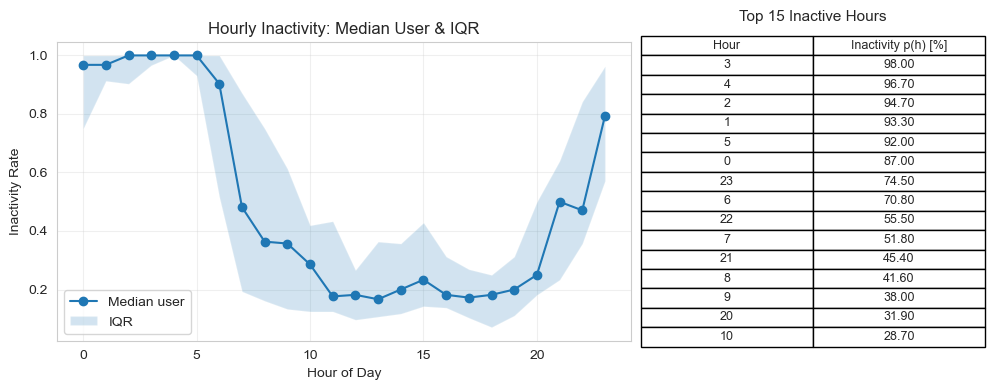

In [88]:
df = hourly_cleaned_final.copy()
df["InactiveHour"] = df["StepTotal"] < 100

user_hour = (
    df.groupby(["Id","Hour"])["InactiveHour"].mean()
      .reset_index()
)

hour_cohort = (
    user_hour.groupby("Hour")["InactiveHour"]
             .agg(Median="median",
                  Q1=lambda x: x.quantile(0.25),
                  Q3=lambda x: x.quantile(0.75))
             .reset_index()
)

hour_rates = (
    df.groupby("Hour")["InactiveHour"].mean()
      .reset_index(name="InactivityRate")
      .sort_values("InactivityRate", ascending=False)
      .assign(InactivityPct=lambda d: (d["InactivityRate"]*100).round(1))
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={'width_ratios':[2, 1]})

axes[0].plot(hour_cohort["Hour"], hour_cohort["Median"], marker="o", label="Median user")
axes[0].fill_between(hour_cohort["Hour"], hour_cohort["Q1"], hour_cohort["Q3"], alpha=0.2, label="IQR")
axes[0].set_title("Hourly Inactivity: Median User & IQR")
axes[0].set_xlabel("Hour of Day")
axes[0].set_ylabel("Inactivity Rate")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].axis("off")
table_data = (
    hour_rates.head(15)[["Hour", "InactivityPct"]]
    .rename(columns={"InactivityPct": "Inactivity p(h) [%]"})
    .assign(
        Hour=lambda d: d["Hour"].astype(int),
        **{"Inactivity p(h) [%]": lambda d: d["Inactivity p(h) [%]"].map(lambda x: f"{x:.2f}")}
    )
)
table = axes[1].table(cellText=table_data.values,
                      colLabels=table_data.columns,
                      cellLoc='center', loc='center')
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1.2, 1.2)
axes[1].set_title("Top 15 Inactive Hours", fontsize=11, pad=15)

plt.tight_layout()
plt.show()

### Interpretation
- Overnight period (21:00 - 6:00): Inactivity remains extremely high (>50%), indicating near-universal sleep and wake time
- Morning transition (6:00 - 9:00): Sharp fall off in inactivity as participants wake and begin daily movement, leading to a steady decline then on
- Daytime period (9:00 – 21:00): Inactivity stays relatively low (around 20-30% as shown in the graph above), reflecting active hours
- Midday uptick (14:00 – 16:00): A small secondary rise suggests lunch breaks or short rest periods, consistent with midday pauses in activity
- IQR width: The narrower overnight IQR indicates consistent inactivity, whereas wider ones during the day show greater lifestyle variability

In [89]:
daytime = hour_cohort[(hour_cohort["Hour"] >= 11) & (hour_cohort["Hour"] <= 19)]

top3_daytime = (
    daytime.sort_values("Median", ascending=False)
    .assign(MedianPct=lambda d: (d["Median"]*100).round(1))
    .head(3)
)
display(top3_daytime)

nighttime = hour_cohort[
    (hour_cohort["Hour"] < 11) | (hour_cohort["Hour"] > 19)
]
night_avg = nighttime["Median"].mean() * 100
day_avg = daytime["Median"].mean() * 100

,Hour,Median,Q1,Q3,MedianPct
15,15,0.233333,0.142857,0.428571,23.3
14,14,0.200000,0.117647,0.357143,20.0
19,19,0.200000,0.111111,0.312500,20.0


### Interpretation
A small secondary inactivity peak appears between 14:00–16:00, which we suspect might be a post-lunch rest period or sedentary work/study phase.

This supports the presence of a bimodal daily rhythm - a major nighttime sleep phase and a minor daytime lull.

### Feature engineering

The following definitions are made before feature engineering:
- *Morning*: 6:00AM to 11:00AM
- *Afternoon*: 2:00PM to 6:00PM
- *Evening*: 7:00PM to 10:00PM
- *Late night*: 10:00PM to 6:00AM(second day)
- *Weekend*: Saturday and Sunday
- *Low activity days*: Days less than 1000 steps
****
Compute and generate a table of the use features(full description are in Appendix **1.1**)

In [90]:
# Define time periods
morning_hours = list(range(6, 11))  # 6 AM–11 AM
afternoon_hours = list(range(14, 18))  #  2PM–6 PM
evening_hours = list(range(19, 22))  # 7 PM–10 PM
late_night_hours = list(range(22, 24)) + list(range(0, 6))  # 10 PM–6 AM

# Assign time periods to hourly data
hourly_cleaned_final['Time_Period'] = pd.cut(
    hourly_cleaned_final['Hour'],
    bins=[0, 6, 11, 16, 22, 24],
    labels=['LateNight', 'Morning', 'Afternoon', 'Evening', 'LateNight'],
    include_lowest=True,
    ordered=False
)

# Calculate average steps per time period per user
hourly_features = hourly_cleaned_final.groupby(['Id', 'Time_Period'], observed=True)[
    'StepTotal'].mean().unstack().reset_index()
hourly_features.columns = ['Id', 'Avg_LateNight_Steps',
                           'Avg_Morning_Steps', 'Avg_Afternoon_Steps', 'Avg_Evening_Steps']
hourly_features = hourly_features.fillna(0)

# Calculate proportion of steps in each period
hourly_features['Total_Steps'] = (
    hourly_features['Avg_Morning_Steps'] +
    hourly_features['Avg_Afternoon_Steps'] +
    hourly_features['Avg_Evening_Steps'] +
    hourly_features['Avg_LateNight_Steps']
)
hourly_features['Prop_Morning_Steps'] = hourly_features['Avg_Morning_Steps'] / \
    hourly_features['Total_Steps']
hourly_features['Prop_Afternoon_Steps'] = hourly_features['Avg_Afternoon_Steps'] / \
    hourly_features['Total_Steps']
hourly_features['Prop_Evening_Steps'] = hourly_features['Avg_Evening_Steps'] / \
    hourly_features['Total_Steps']
hourly_features['Prop_LateNight_Steps'] = hourly_features['Avg_LateNight_Steps'] / \
    hourly_features['Total_Steps']
hourly_features = hourly_features.fillna(0)


# Daily-level features
daily_cleaned_final['Is_Weekend'] = pd.to_datetime(
    daily_cleaned_final['Date']).dt.weekday >= 5  # Saturday/Sunday
daily_features = daily_cleaned_final.groupby('Id').agg({
    'StepTotal': ['mean', 'std', lambda x: (x < 1000).mean()],
    # Proportion of weekend days (for validation)
    'Is_Weekend': lambda x: (x == True).mean()
}).reset_index()
daily_features.columns = ['Id', 'Avg_Daily_Steps',
                          'Std_Daily_Steps', 'Prop_Low_Activity_Days', 'Prop_Weekend_Days']
daily_features['Std_Daily_Steps'] = daily_features['Std_Daily_Steps'].fillna(0)

# Weekday vs. weekend step averages
weekday_weekend_features = daily_cleaned_final.groupby(['Id', 'Is_Weekend'])[
    'StepTotal'].mean().unstack().reset_index()
weekday_weekend_features.columns = [
    'Id', 'Avg_Weekday_Steps', 'Avg_Weekend_Steps']
weekday_weekend_features = weekday_weekend_features.fillna(0)

# Hourly variance
hourly_variance = hourly_cleaned_final.groupby(
    'Id')['StepTotal'].std().reset_index()
hourly_variance.columns = ['Id', 'Hourly_Step_Variance']

# Merge features
features_df = daily_features.merge(hourly_features, on='Id', how='inner')
features_df = features_df.merge(weekday_weekend_features, on='Id', how='inner')
features_df = features_df.merge(hourly_variance, on='Id', how='left').fillna(0)

features_df.head()

,Id,Avg_Daily_Steps,Std_Daily_Steps,Prop_Low_Activity_Days,Prop_Weekend_Days,Avg_LateNight_Steps,Avg_Morning_Steps,Avg_Afternoon_Steps,Avg_Evening_Steps,Total_Steps,Prop_Morning_Steps,Prop_Afternoon_Steps,Prop_Evening_Steps,Prop_LateNight_Steps,Avg_Weekday_Steps,Avg_Weekend_Steps,Hourly_Step_Variance
0,1503960366,12116.741935,3052.484201,0.032258,0.258065,601.046667,1055.735955,122.619247,447.746667,2227.148535,0.474030,0.055057,0.201040,0.269873,12239.478261,11763.875,836.484941
1,1624580081,5743.903226,6177.048612,0.000000,0.258065,265.441558,288.338889,51.506073,466.122581,1071.409101,0.269121,0.048073,0.435056,0.247750,4516.434783,9272.875,760.458172
2,1644430081,7282.966667,4325.478825,0.000000,0.266667,376.262069,724.873563,33.598326,194.740000,1329.473959,0.545233,0.025272,0.146479,0.283016,6365.136364,9807.000,589.610641
3,1844505072,4822.250000,1796.599733,0.000000,0.250000,332.775000,291.437500,30.765625,232.225000,887.203125,0.328490,0.034677,0.261750,0.375083,5136.083333,3880.750,280.856960
4,1927972279,2084.454545,1152.930819,0.272727,0.181818,147.654545,113.757576,3.590909,126.981818,391.984848,0.290209,0.009161,0.323946,0.376684,1920.000000,2824.500,234.848218


## Sleep/Wake Period Detection


This section identifies each user's typical sleep/wake pattern and classifies users into different groups based on their behaviours. Accurate sleep detection is essential for answering our driving question about how sleep/wake timing relates to activity levels.

### Sleep Period Detection

We detect sleep periods for each user using a multi-step algorithm:
1. Calculate hourly activity profile: For each user, we compute the average step count for each hour of the day (0-23) across all observation days. This produces a 24-hour activity pattern for each individual.
2. Identify low-activity hours: We find hours where average activity falls below the user's 30th percentile activity level, or below an absolute threshold of 100 steps per hour. These hours represent candidates for sleep periods.
3. Find consecutive sequences: We search for sequences of at least 4 consecutive low-activity hours. This minimum duration ensures we identify real sleep periods.
4. Select primary sleep period: If multiple sequences exist, we select the longest one as the primary sleep period. For most users, this identifies a single continuous sleep period.
5. Define sleep/wake times: The sleep_start is the first hour of the identified sequence, sleep_end is the last hour, and wake_time is defined as sleep_end + 1 hour. We also calculate sleep_duration as the length of the sequence.

In [91]:
def detect_sleep_wake_times(hourly_df, step_threshold=100, min_consecutive_hours=4):
    sleep_stats = []

    for user_id in hourly_df['Id'].unique():
        user_data = hourly_df[hourly_df['Id'] == user_id].sort_values('DateTime')

        # Calculate average steps by hour of day (0-23)
        hourly_avg = user_data.groupby('Hour')['StepTotal'].mean().sort_index()

        # Identify potential sleep hours using 30th percentile
        sleep_threshold_user = hourly_avg.quantile(0.3)

        # Find hours with activity below both thresholds
        low_activity_hours = hourly_avg[hourly_avg < min(step_threshold, sleep_threshold_user)].index.tolist()

        if len(low_activity_hours) >= min_consecutive_hours:
            # Find consecutive sequences (accounting for midnight wraparound)
            sequences = []
            current_seq = [low_activity_hours[0]]

            for i in range(1, len(low_activity_hours)):
                # Check if consecutive (including wraparound: 23 -> 0)
                if low_activity_hours[i] == (low_activity_hours[i-1] + 1) % 24 or \
                   (low_activity_hours[i-1] == 23 and low_activity_hours[i] == 0):
                    current_seq.append(low_activity_hours[i])
                else:
                    if len(current_seq) >= min_consecutive_hours:
                        sequences.append(current_seq)
                    current_seq = [low_activity_hours[i]]

            # Don't forget the last sequence
            if len(current_seq) >= min_consecutive_hours:
                sequences.append(current_seq)

            # Select the longest sequence as primary sleep period
            if sequences:
                sleep_period = max(sequences, key=len)
                sleep_start = min(sleep_period)
                sleep_end = max(sleep_period)
                sleep_duration = len(sleep_period)

                # Calculate wake time (end of sleep + 1 hour)
                wake_time = (sleep_end + 1) % 24

                # Calculate average activity during sleep vs wake
                sleep_avg = user_data[user_data['Hour'].isin(sleep_period)]['StepTotal'].mean()
                wake_hours = [h for h in range(24) if h not in sleep_period]
                wake_avg = user_data[user_data['Hour'].isin(wake_hours)]['StepTotal'].mean()

                sleep_stats.append({
                    'Id': user_id,
                    'sleep_start': sleep_start,
                    'sleep_end': sleep_end,
                    'wake_time': wake_time,
                    'sleep_duration': sleep_duration,
                    'avg_sleep_steps': sleep_avg,
                    'avg_wake_steps': wake_avg,
                    'total_days': user_data['Date'].nunique()
                })

    return pd.DataFrame(sleep_stats)

# Detect sleep/wake patterns using cleaned data
sleep_wake_df = detect_sleep_wake_times(hourly_cleaned_final, step_threshold=100, min_consecutive_hours=4)

print(f"\nSleep/Wake Detection Results:")
print(f"   • Users with detected sleep patterns: {len(sleep_wake_df)} of {hourly_cleaned_final['Id'].nunique()}")
print(f"   • Detection success rate: {len(sleep_wake_df)/hourly_cleaned_final['Id'].nunique()*100:.1f}%")
print(f"   • Average sleep duration: {sleep_wake_df['sleep_duration'].mean():.1f} hours (SD: {sleep_wake_df['sleep_duration'].std():.1f})")
print(f"   • Average sleep start time: {sleep_wake_df['sleep_start'].mean():.1f}:00")
print(f"   • Average wake time: {sleep_wake_df['wake_time'].mean():.1f}:00")


Sleep/Wake Detection Results:
   • Users with detected sleep patterns: 32 of 33
   • Detection success rate: 97.0%
   • Average sleep duration: 6.2 hours (SD: 0.9)
   • Average sleep start time: 0.3:00
   • Average wake time: 6.5:00


### Sleep/Wake Classification

Based on detected sleep and wake times, we classify each user into four groups:

Sleep Timing Classification:
- Early Sleeper: Sleep start time before 0:00 (12 PM)
- Late Sleeper: Sleep start time at or after 0:00

Wake Timing Classification:
- Early Riser: Wake time before 7:00 AM
- Late Riser: Wake time at or after 7:00 AM

This produces four combined groups:
- Early Sleeper / Early Riser
- Early Sleeper / Late Riser
- Late Sleeper / Early Riser
- Late Sleeper / Late Riser

In [92]:
def classify_sleep_schedule(row):
    # Sleep classification
    if row['sleep_start'] > 0:
        sleep_type = 'Late Sleeper'
    else:
        sleep_type = 'Early Sleeper'

    # Wake classification
    if row['wake_time'] < 7:
        wake_type = 'Early Riser'
    else:
        wake_type = 'Late Riser'

    return pd.Series({'sleep_type': sleep_type, 'wake_type': wake_type})

# Apply classification
sleep_wake_df[['sleep_type', 'wake_type']] = sleep_wake_df.apply(classify_sleep_schedule, axis=1)

# Create combined sleep-wake pattern groups
sleep_wake_df['sleep_wake_pattern'] = sleep_wake_df['sleep_type'] + ' / ' + sleep_wake_df['wake_type']

print(f"\nSleep/Wake Pattern Distribution:")
pattern_counts = sleep_wake_df['sleep_wake_pattern'].value_counts()
for pattern, count in pattern_counts.items():
    print(f"   • {pattern}: {count} users ({count/len(sleep_wake_df)*100:.1f}%)")

print(f"\nSample of detected sleep/wake times (first 10 users):")
print(sleep_wake_df[['Id', 'sleep_start', 'sleep_end', 'wake_time', 'sleep_duration', 'sleep_wake_pattern']].head(10).to_string(index=False))


Sleep/Wake Pattern Distribution:
   • Early Sleeper / Early Riser: 18 users (56.2%)
   • Late Sleeper / Late Riser: 7 users (21.9%)
   • Early Sleeper / Late Riser: 7 users (21.9%)

Sample of detected sleep/wake times (first 10 users):
        Id  sleep_start  sleep_end  wake_time  sleep_duration          sleep_wake_pattern
1503960366            1          7          8               7   Late Sleeper / Late Riser
1624580081            0          5          6               6 Early Sleeper / Early Riser
1644430081            0          6          7               7  Early Sleeper / Late Riser
1844505072            1          7          8               7   Late Sleeper / Late Riser
1927972279            0          3          4               4 Early Sleeper / Early Riser
2022484408            0          5          6               6 Early Sleeper / Early Riser
2026352035            0          4          5               5 Early Sleeper / Early Riser
2320127002            0          5         

### Validation of Sleep Detection

To validate our detected sleep periods, we examine activity levels during identified sleep versus wake hours.

In [93]:
print(f"\nValidation of Sleep Detection:")
print(f"   • Average steps during sleep hours: {sleep_wake_df['avg_sleep_steps'].mean():.1f} steps/hour")
print(f"   • Average steps during wake hours: {sleep_wake_df['avg_wake_steps'].mean():.1f} steps/hour")
print(f"   • Wake/Sleep activity ratio: {(sleep_wake_df['avg_wake_steps'].mean() / sleep_wake_df['avg_sleep_steps'].mean()):.1f}:1")


Validation of Sleep Detection:
   • Average steps during sleep hours: 14.6 steps/hour
   • Average steps during wake hours: 465.5 steps/hour
   • Wake/Sleep activity ratio: 31.9:1


### Visualization: Sleep/Wake Distribution

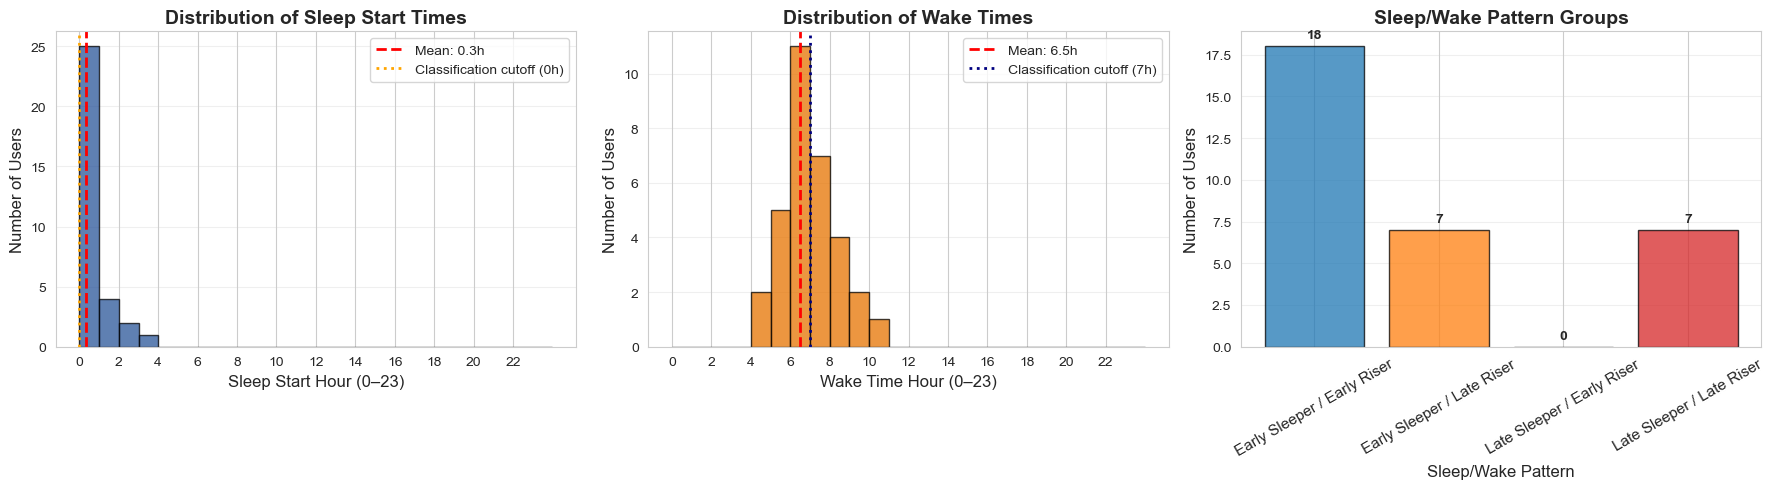

In [94]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Sleep start time distribution
axes[0].hist(sleep_wake_df['sleep_start'].dropna(), bins=range(0, 25),
             color='#2a5599', alpha=0.75, edgecolor='black')
axes[0].axvline(x=sleep_wake_df['sleep_start'].mean(), color='red', linestyle='--',
                linewidth=2, label=f"Mean: {sleep_wake_df['sleep_start'].mean():.1f}h")
axes[0].axvline(x=0, color='orange', linestyle=':', linewidth=2, label='Classification cutoff (0h)')
axes[0].set_xlabel('Sleep Start Hour (0–23)', fontsize=12)
axes[0].set_ylabel('Number of Users', fontsize=12)
axes[0].set_title('Distribution of Sleep Start Times', fontsize=14, fontweight='bold')
axes[0].set_xticks(range(0, 24, 2))
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='y')

# Wake time distribution
axes[1].hist(sleep_wake_df['wake_time'].dropna(), bins=range(0, 25),
             color='#e67300', alpha=0.75, edgecolor='black')
axes[1].axvline(x=sleep_wake_df['wake_time'].mean(), color='red', linestyle='--',
                linewidth=2, label=f"Mean: {sleep_wake_df['wake_time'].mean():.1f}h")
axes[1].axvline(x=7, color='navy', linestyle=':', linewidth=2, label='Classification cutoff (7h)')
axes[1].set_xlabel('Wake Time Hour (0–23)', fontsize=12)
axes[1].set_ylabel('Number of Users', fontsize=12)
axes[1].set_title('Distribution of Wake Times', fontsize=14, fontweight='bold')
axes[1].set_xticks(range(0, 24, 2))
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')

# Sleep/wake pattern groups
pattern_order = ['Early Sleeper / Early Riser',
                 'Early Sleeper / Late Riser',
                 'Late Sleeper / Early Riser',
                 'Late Sleeper / Late Riser']
pattern_counts = sleep_wake_df['sleep_wake_pattern'].value_counts().reindex(pattern_order, fill_value=0)

bars = axes[2].bar(pattern_counts.index, pattern_counts.values,
                   color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'], alpha=0.75, edgecolor='black')
axes[2].set_xlabel('Sleep/Wake Pattern', fontsize=12)
axes[2].set_ylabel('Number of Users', fontsize=12)
axes[2].set_title('Sleep/Wake Pattern Groups', fontsize=14, fontweight='bold')
axes[2].tick_params(axis='x', rotation=30, labelsize=11)
axes[2].grid(True, alpha=0.3, axis='y')

# Add count labels above bars
for bar in bars:
    height = bar.get_height()
    axes[2].text(bar.get_x() + bar.get_width() / 2, height + 0.3,
                 f'{int(height)}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# plt.savefig('sleep_wake_detection.png', dpi=300, bbox_inches='tight')

### Interpretation

The sleep detection algorithm successfully identified sleep patterns for most users. The distribution shows:
- Sleep start times concentrate between 0-1 AM, with a tail extending to 2-3 AM for late sleepers
- Wake times show broader distribution from 5 AM to 10 AM, with most users waking between 6-8 AM
- The most common pattern is Early Sleeper / Early Riser, representing traditional sleep behaviors
- The least common pattern is Late Sleeper / Early Riser, suggesting late bedtimes typically pair with later wake times rather than shortened sleep

The large wake/sleep activity ratio confirms that our algorithm successfully distinguishes real sleep from wake periods. This validates using consecutive low-activity hours as a proxy for sleep in the absence of direct sleep measurement devices.

# Results in relation to Driving Question

## Sleep Times Impacts on Activity Levels

In [95]:
# we use sleep_wake_df which was used to hold all the participants sleep and wake times and categories

from scipy.stats import shapiro
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import statsmodels.api as sm

def compact_summary(model):
    df = pd.DataFrame({
        "coef": model.params,
        "t": model.tvalues,
        "p": model.pvalues
    }).round(4)
    print(f"p = {model.f_pvalue:.4f}")
    print(f"R² = {model.rsquared:.3f} | Adj R² = {model.rsquared_adj:.3f}")
    print(f"Adj R² = {model.rsquared_adj:.3f}")
    print(f"F-statistic: {model.fvalue:.3f}")
    return df

features_merged = features_df.merge(sleep_wake_df, on='Id', how='right')

Here we compare early sleep vs late to avg daily steps for participants via a box plot and corresponding t-test to analyse potential patterns, and view if those patterns may be significant. (Shall we even include this with just 6 early sleepers?)

C:\Users\JOHN GUO\AppData\Local\Temp\ipykernel_38400\3088476776.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


<Axes: xlabel='Sleep time category', ylabel='Overall Average Steps (per hour)'>

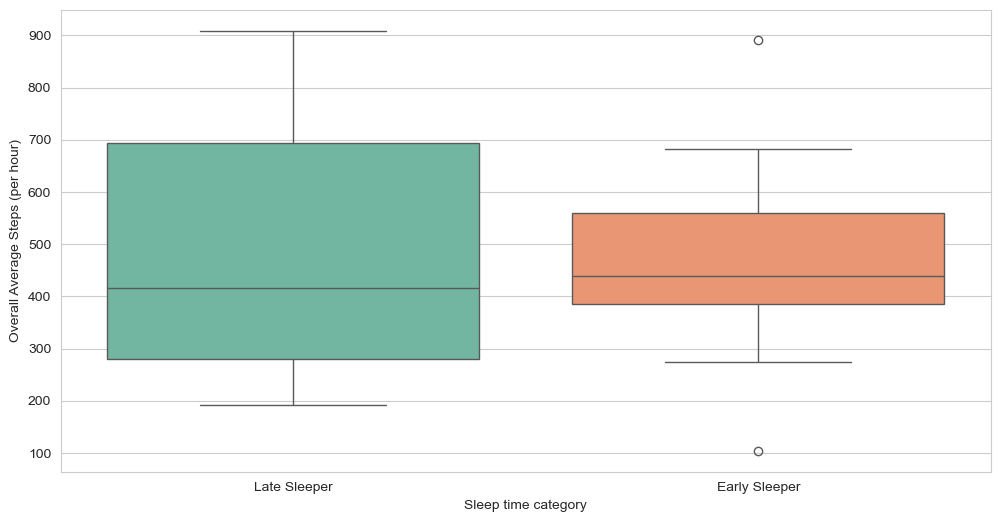

In [96]:
sleep_wake_df['Overall Average Steps (per hour)'] = sleep_wake_df['avg_wake_steps']
sleep_wake_df['Sleep time category'] = sleep_wake_df['sleep_type']

sns.boxplot(
    x='Sleep time category',
    y='Overall Average Steps (per hour)',
    data=sleep_wake_df,
    palette='Set2'
)

As can be seen by the side-by-side box plots, there doesn't appear to be a huge difference between the average steps for those who wake up early and those who wake up late. It appears the early sleepers range is more tight than late sleepers though this can be attributed to the small sample of late sleepers (just 6).

To perform the two-sample t-test, we need test 3 assumptions:
1. Independence of observations
2. Normality of residuals
3. Homoscedascticity of residuals

**Independence of observations**

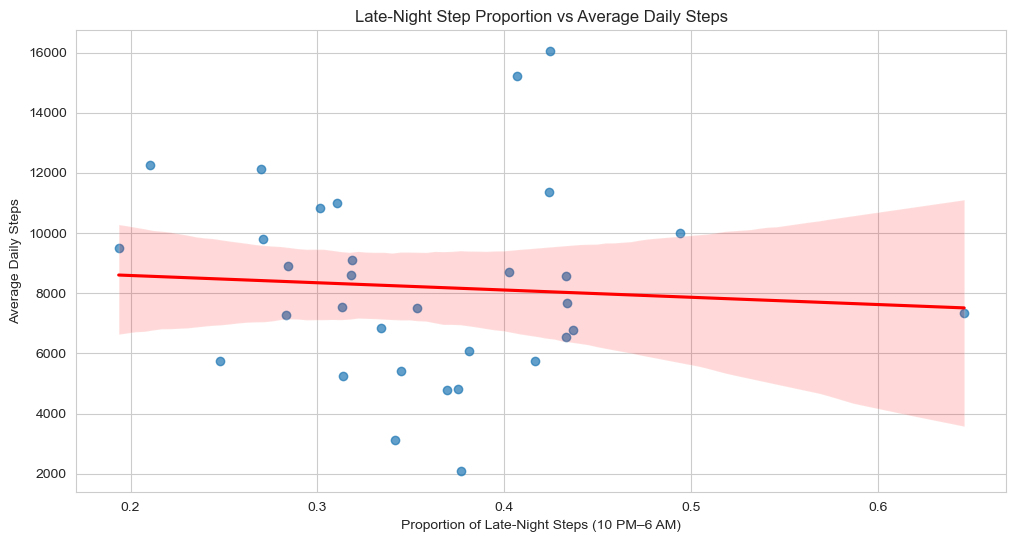

In [97]:
sns.regplot(
    data=features_merged,
    x='Prop_LateNight_Steps', y='Avg_Daily_Steps',
    scatter_kws={'alpha': 0.7}, line_kws={'color': 'red'}
)
plt.title('Late-Night Step Proportion vs Average Daily Steps')
plt.xlabel('Proportion of Late-Night Steps (10 PM–6 AM)')
plt.ylabel('Average Daily Steps')
plt.show()

The graph shows no correlation between proportion of late-night steps and average daily steps prior to the t-test.

**Normality of residuals**

Hypothesis for Shapiro-Wilk test:

$H_{0}$(p > 0.05): The data is normally distributed\
$H_{1}$(p < 0.05): The data significantly deviates from a normal distribution

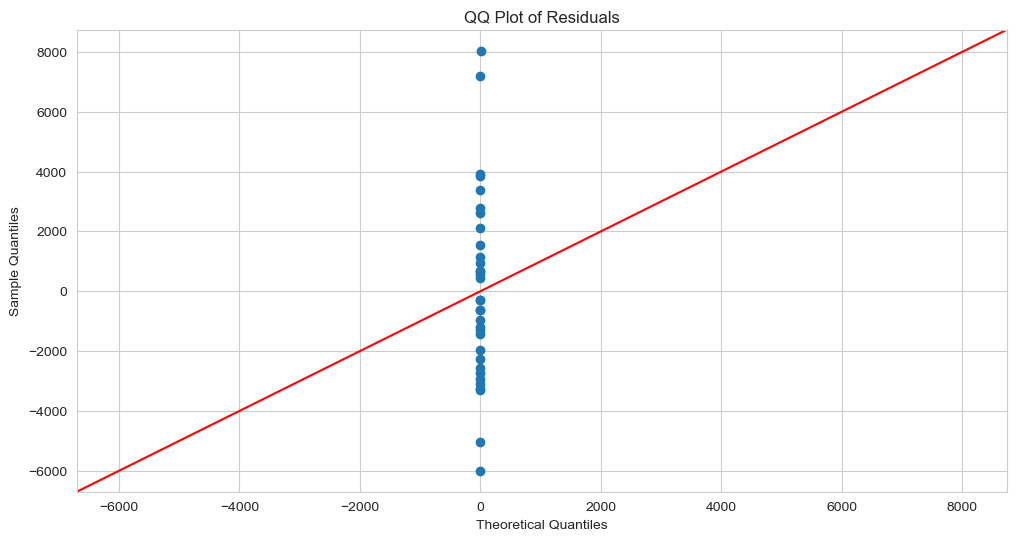

Shapiro-Wilk: ShapiroResult(statistic=0.9683166372726082, pvalue=0.43517171327550547)


In [98]:
X = sm.add_constant(features_df['Prop_LateNight_Steps'])
y = features_df['Avg_Daily_Steps']
model = sm.OLS(y, X).fit()

residuals = model.resid
sm.qqplot(residuals, line='45')
plt.title("QQ Plot of Residuals")
plt.show()

print("Shapiro-Wilk:", shapiro(residuals))

The QQ-plot shows no signs of extreme distribution and Shapiro-Wilk test return with a p-value much larger than 0.05, so a normal distribution can be assumed.

**Homoscedascticity of residuals**

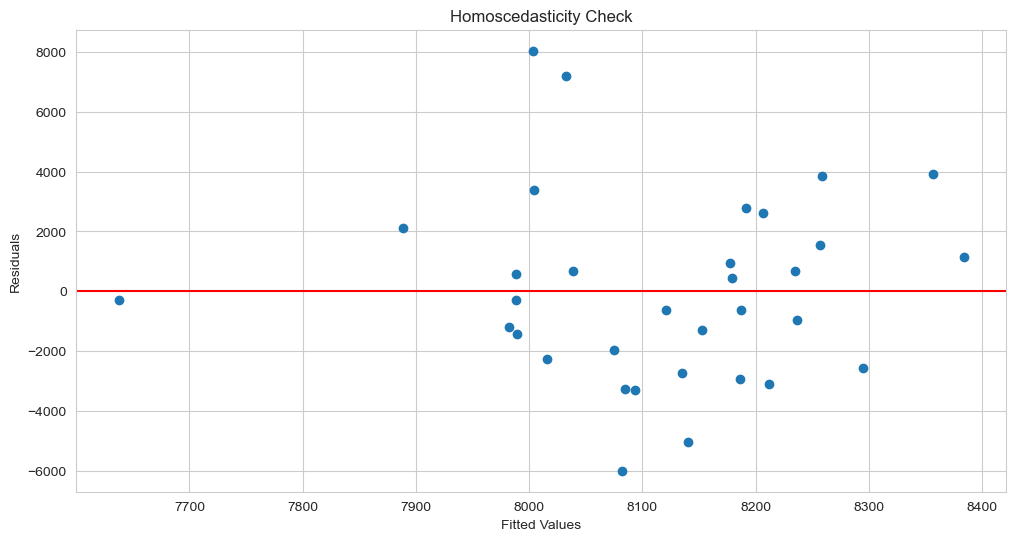

In [99]:
plt.scatter(model.fittedvalues, residuals)
plt.axhline(0, color='red')
plt.xlabel('Fitted Values')
plt.ylabel('Residuals')
plt.title('Homoscedasticity Check')
plt.show()

Since there is no correlation in the first place, homoscedascticity is not a issue.

In [100]:
# Split into high and low groups
high_ln = features_merged[features_merged['sleep_type'] == 'Early Sleeper']
low_ln = features_merged[features_merged['sleep_type'] == 'Late Sleeper']

# Compare overall activity
t_stat, p_value = stats.ttest_ind(high_ln['avg_wake_steps'], low_ln['avg_wake_steps'])

print(f"\nComparison of Overall Activity Levels:")
print(f"   • High late-night group: {high_ln['avg_wake_steps'].mean():.1f} steps/hour (SD: {high_ln['avg_wake_steps'].std():.1f})")
print(f"   • Low late-night group: {low_ln['avg_wake_steps'].mean():.1f} steps/hour (SD: {low_ln['avg_wake_steps'].std():.1f})")
print(f"   • Difference: {abs(high_ln['avg_wake_steps'].mean() - low_ln['avg_wake_steps'].mean()):.1f} steps/hour")
print(f"\nTwo-sample t-test results:")
print(f"   • t-statistic: {t_stat:.3f}")
print(f"   • p-value: {p_value:.4f}")

if p_value < 0.05:
    direction = "higher" if high_ln['overall_avg'].mean() > low_ln['overall_avg'].mean() else "lower"
    print(f"   • ✓ Result: STATISTICALLY SIGNIFICANT (p < 0.05)")
    print(f"   • Interpretation: High late-night activity is associated with {direction} overall activity")
else:
    print(f"   • Result: Not statistically significant (p ≥ 0.05)")
    print(f"   • Interpretation: Sleep time does not significantly predict overall activity levels")


Comparison of Overall Activity Levels:
   • High late-night group: 457.2 steps/hour (SD: 156.6)
   • Low late-night group: 495.1 steps/hour (SD: 272.0)
   • Difference: 37.9 steps/hour

Two-sample t-test results:
   • t-statistic: -0.477
   • p-value: 0.6365
   • Result: Not statistically significant (p ≥ 0.05)
   • Interpretation: Sleep time does not significantly predict overall activity levels


The t-test further demonstrates the impact of sleep time doesn't have a significant impact in predicting overall activity.

## Wake Times Impacts on Activity Levels

Here we compare early riding time vs late to avg daily steps for participants via a box plot and corresponding t-test to analyse potential patterns, and view if those patterns may be significant.

C:\Users\JOHN GUO\AppData\Local\Temp\ipykernel_38400\2736040611.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


<Axes: xlabel='Wake time category', ylabel='Overall Average Steps (per hour)'>

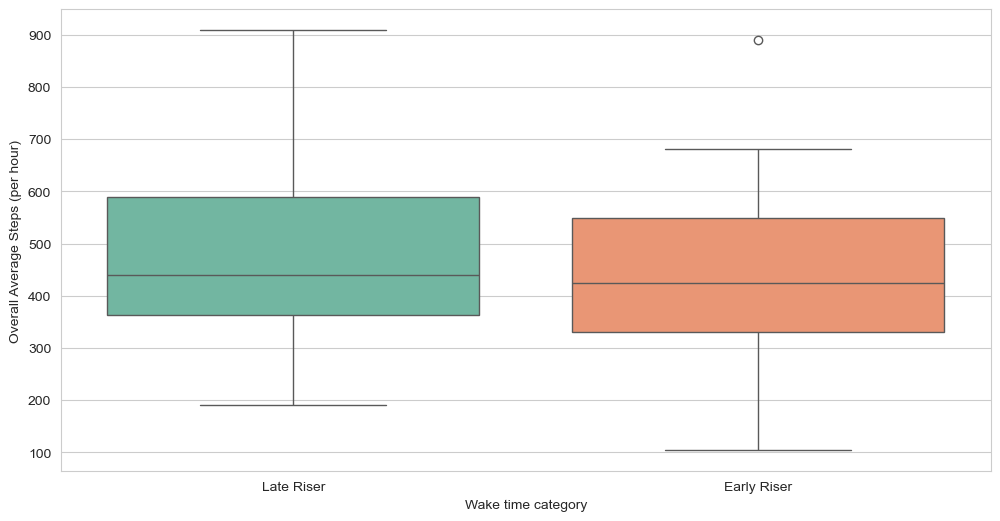

In [101]:
sleep_wake_df['Wake time category'] = sleep_wake_df['wake_type']

sns.boxplot(
    x='Wake time category',
    y='Overall Average Steps (per hour)',
    data=sleep_wake_df,
    palette='Set2'
)

It appears a later wake-up time does show signs of a slight higher average steps per day, though this difference is rather miniscule and is unlikely to show up on the t-test.

In [102]:
# Split into high and low groups
high_ln = features_merged[features_merged['wake_type'] == 'Early Riser']
low_ln = features_merged[features_merged['wake_type'] == 'Late Riser']

# Compare overall activity
t_stat, p_value = stats.ttest_ind(high_ln['avg_wake_steps'], low_ln['avg_wake_steps'])

print(f"\nComparison of Overall Activity Levels:")
print(f"   • High late-night group: {high_ln['avg_wake_steps'].mean():.1f} steps/hour (SD: {high_ln['avg_wake_steps'].std():.1f})")
print(f"   • Low late-night group: {low_ln['avg_wake_steps'].mean():.1f} steps/hour (SD: {low_ln['avg_wake_steps'].std():.1f})")
print(f"   • Difference: {abs(high_ln['avg_wake_steps'].mean() - low_ln['avg_wake_steps'].mean()):.1f} steps/hour")
print(f"\nTwo-sample t-test results:")
print(f"   • t-statistic: {t_stat:.3f}")
print(f"   • p-value: {p_value:.4f}")

if p_value < 0.05:
    direction = "higher" if high_ln['overall_avg'].mean() > low_ln['overall_avg'].mean() else "lower"
    print(f"   • ✓ Result: STATISTICALLY SIGNIFICANT (p < 0.05)")
    print(f"   • Interpretation: High late-night activity is associated with {direction} overall activity")
else:
    print(f"   • Result: Not statistically significant (p ≥ 0.05)")
    print(f"   • Interpretation: Wake time does not significantly predict overall activity levels")


Comparison of Overall Activity Levels:
   • High late-night group: 451.6 steps/hour (SD: 178.0)
   • Low late-night group: 483.3 steps/hour (SD: 194.9)
   • Difference: 31.6 steps/hour

Two-sample t-test results:
   • t-statistic: -0.478
   • p-value: 0.6358
   • Result: Not statistically significant (p ≥ 0.05)
   • Interpretation: Wake time does not significantly predict overall activity levels


As predicted, wake-up time doesn't appear to affect overall activity levels.

## Late-Night Activity Impacts on Activity Levels

This section focuses specifically on late-night activity (12 PM - 4 AM) to investigate whether individuals with higher late-night activity represent a distinct behavioral type and whether late-night activity relates to overall activity patterns.


### Defining Late-Night Activity

We operationalize "late-night activity" as the average hourly step count during the window from 22:00 (10 PM) to 04:00 the following morning. This 6-hour window captures both pre-sleep evening hours and the core sleep period. We also calculate a late-night ratio: (late-night average steps) / (daytime average steps), where daytime is defined as 6 AM - 10 PM.

Users are classified into two groups based on whether their late-night ratio exceeds the population median:
- High Late-Night Activity: Ratio above median
- Low Late-Night Activity: Ratio below median

This classification is independent of the sleep/wake timing classification from Section 3, allowing us to examine whether late-night activity represents an additional dimension of variation beyond sleep timing.

In [103]:
# Define late-night hours (22:00 - 04:00)
late_night_hours = list(range(22, 24)) + list(range(0, 5))

def calculate_late_night_score(hourly_df):
    late_night_data = hourly_df[hourly_df['Hour'].isin(late_night_hours)]
    daytime_hours = [h for h in range(24) if h not in late_night_hours]
    daytime_data = hourly_df[hourly_df['Hour'].isin(daytime_hours)]

    user_stats = []
    for user_id in hourly_df['Id'].unique():
        ln_steps = late_night_data[late_night_data['Id'] == user_id]['StepTotal'].mean()
        dt_steps = daytime_data[daytime_data['Id'] == user_id]['StepTotal'].mean()
        total_steps = hourly_df[hourly_df['Id'] == user_id]['StepTotal'].mean()

        user_stats.append({
            'Id': user_id,
            'late_night_avg': ln_steps,
            'daytime_avg': dt_steps,
            'overall_avg': total_steps,
            'late_night_ratio': ln_steps / dt_steps if dt_steps > 0 else 0
        })

    return pd.DataFrame(user_stats)

late_night_scores = calculate_late_night_score(hourly_cleaned_final)

# Merge with sleep/wake patterns
late_night_analysis = late_night_scores.merge(
    sleep_wake_df[['Id', 'sleep_wake_pattern']],
    on='Id', how='inner'
)

print(f"\nLate-Night Activity Metrics:")
print(f"   • Users analyzed: {len(late_night_analysis)}")
print(f"   • Average late-night steps: {late_night_analysis['late_night_avg'].mean():.1f} steps/hour")
print(f"   • Average daytime steps: {late_night_analysis['daytime_avg'].mean():.1f} steps/hour")
print(f"   • Median late-night/daytime ratio: {late_night_analysis['late_night_ratio'].median():.3f}")

# Classify based on median split
late_night_median = late_night_analysis['late_night_ratio'].median()
late_night_analysis['late_night_category'] = late_night_analysis['late_night_ratio'].apply(
    lambda x: 'High Late-Night Activity' if x > late_night_median else 'Low Late-Night Activity'
)

print(f"\nLate-Night Activity Classification:")
ln_counts = late_night_analysis['late_night_category'].value_counts()
for category, count in ln_counts.items():
    print(f"   • {category}: {count} users ({count/len(late_night_analysis)*100:.1f}%)")


Late-Night Activity Metrics:
   • Users analyzed: 32
   • Average late-night steps: 70.6 steps/hour
   • Average daytime steps: 461.0 steps/hour
   • Median late-night/daytime ratio: 0.101

Late-Night Activity Classification:
   • High Late-Night Activity: 16 users (50.0%)
   • Low Late-Night Activity: 16 users (50.0%)


### Statistical Comparison

We compare the two late-night activity groups on overall average activity using an independent samples t-test. This tests whether being active late at night is associated with higher or lower overall activity, or whether it simply represents a different distribution of similar total activity.

In [104]:
# Split into high and low groups
high_ln = late_night_analysis[late_night_analysis['late_night_category'] == 'High Late-Night Activity']
low_ln = late_night_analysis[late_night_analysis['late_night_category'] == 'Low Late-Night Activity']

# Compare overall activity
t_stat, p_value = stats.ttest_ind(high_ln['overall_avg'], low_ln['overall_avg'])

print(f"\nComparison of Overall Activity Levels:")
print(f"   • High late-night group: {high_ln['overall_avg'].mean():.1f} steps/hour (SD: {high_ln['overall_avg'].std():.1f})")
print(f"   • Low late-night group: {low_ln['overall_avg'].mean():.1f} steps/hour (SD: {low_ln['overall_avg'].std():.1f})")
print(f"   • Difference: {abs(high_ln['overall_avg'].mean() - low_ln['overall_avg'].mean()):.1f} steps/hour")
print(f"\nIndependent t-test results:")
print(f"   • t-statistic: {t_stat:.3f}")
print(f"   • p-value: {p_value:.4f}")

if p_value < 0.05:
    direction = "higher" if high_ln['overall_avg'].mean() > low_ln['overall_avg'].mean() else "lower"
    print(f"   • ✓ Result: STATISTICALLY SIGNIFICANT (p < 0.05)")
    print(f"   • Interpretation: High late-night activity is associated with {direction} overall activity")
else:
    print(f"   • Result: Not statistically significant (p ≥ 0.05)")
    print(f"   • Interpretation: Late-night activity does not significantly predict overall activity levels")


Comparison of Overall Activity Levels:
   • High late-night group: 316.6 steps/hour (SD: 131.5)
   • Low late-night group: 376.6 steps/hour (SD: 129.8)
   • Difference: 60.0 steps/hour

Independent t-test results:
   • t-statistic: -1.298
   • p-value: 0.2041
   • Result: Not statistically significant (p ≥ 0.05)
   • Interpretation: Late-night activity does not significantly predict overall activity levels


### Relationship to Sleep/Wake Patterns

We also examine the overlap between late-night activity classification and sleep/wake pattern groups to determine whether late-night activity is primarily driven by later sleep timing or represents additional behavioral variation.

In [105]:
# Cross-tabulation
crosstab = pd.crosstab(
    late_night_analysis['sleep_wake_pattern'],
    late_night_analysis['late_night_category'],
    margins=True,
    normalize='index'
) * 100

print(f"\nPercentage of users in each late-night category by sleep/wake pattern:")
print(crosstab.round(1).to_string())

# Calculate average late-night ratio by sleep/wake pattern
pattern_ln_avg = late_night_analysis.groupby('sleep_wake_pattern')['late_night_ratio'].mean().sort_values()
print(f"\nAverage Late-Night/Daytime Ratio by Sleep/Wake Pattern:")
for pattern, ratio in pattern_ln_avg.items():
    print(f"   • {pattern}: {ratio:.3f}")


Percentage of users in each late-night category by sleep/wake pattern:
late_night_category          High Late-Night Activity  Low Late-Night Activity
sleep_wake_pattern                                                            
Early Sleeper / Early Riser                      22.2                     77.8
Early Sleeper / Late Riser                       71.4                     28.6
Late Sleeper / Late Riser                       100.0                      0.0
All                                              50.0                     50.0

Average Late-Night/Daytime Ratio by Sleep/Wake Pattern:
   • Early Sleeper / Early Riser: 0.097
   • Early Sleeper / Late Riser: 0.162
   • Late Sleeper / Late Riser: 0.357


### Visualization: Late-Night Activity Analysis

C:\Users\JOHN GUO\AppData\Local\Temp\ipykernel_38400\177578736.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


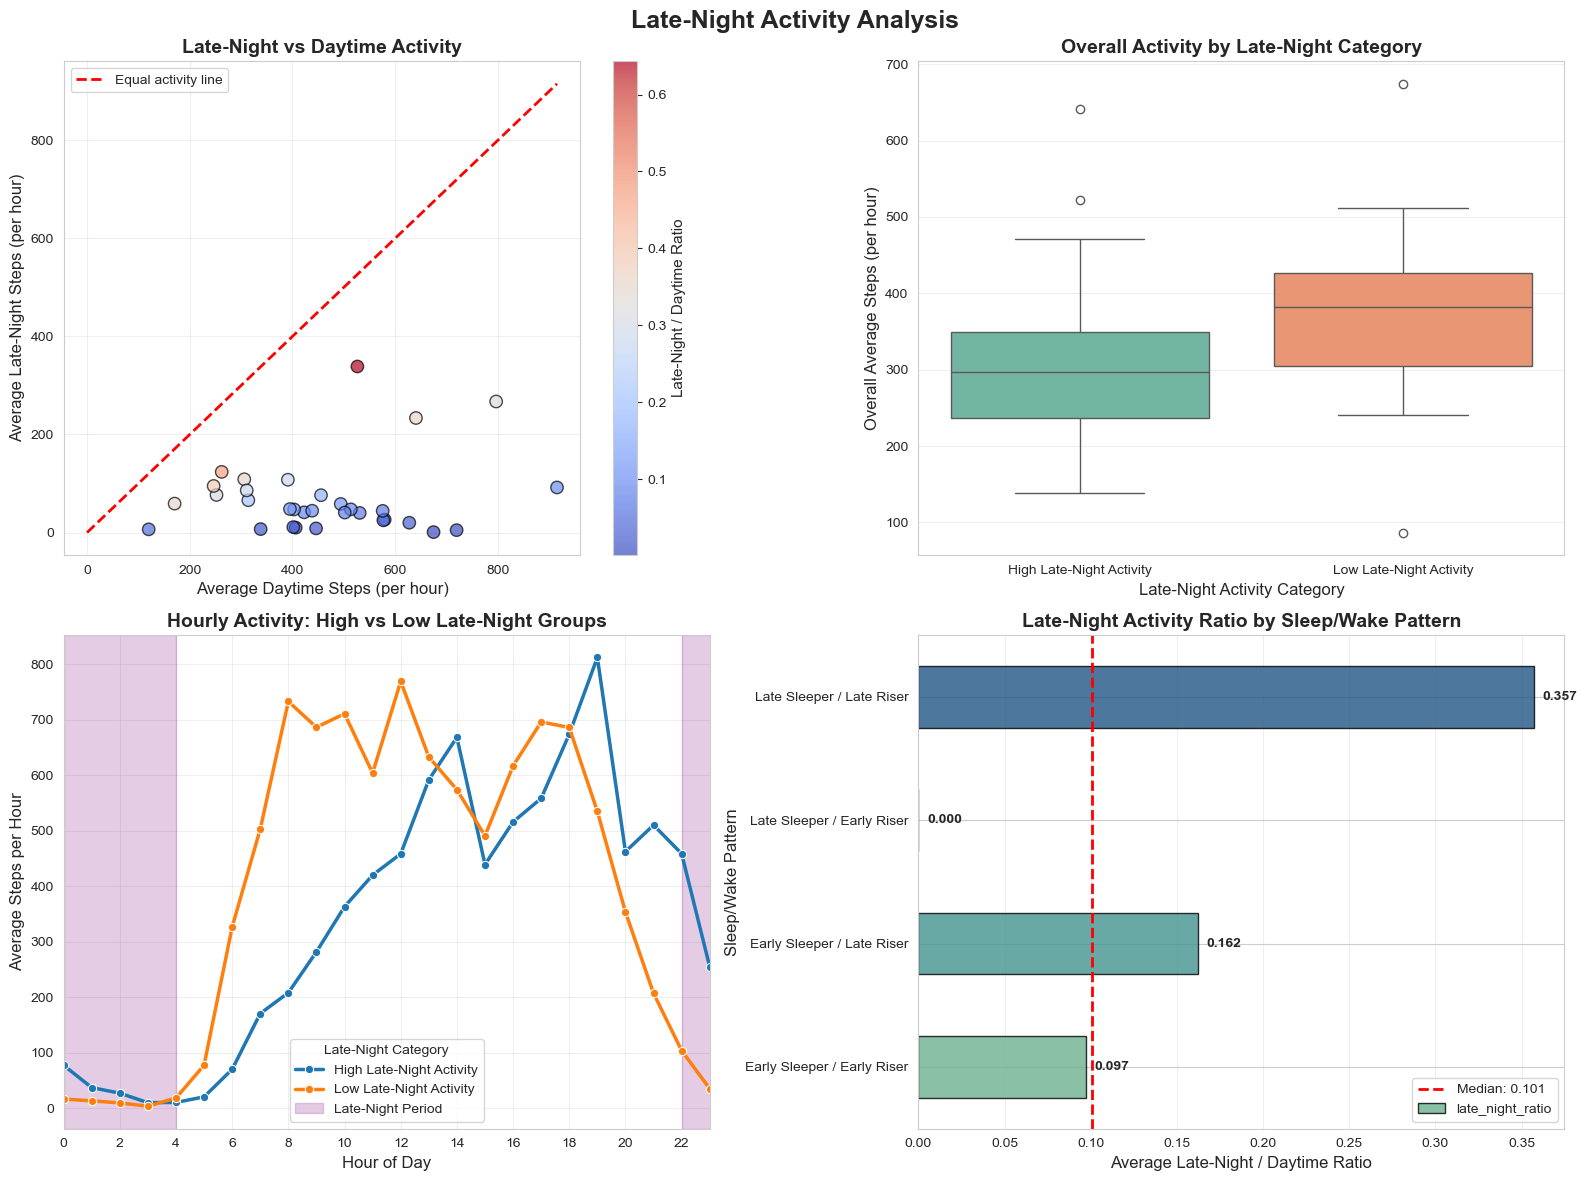

In [106]:
# Create comprehensive late-night activity visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Late-Night Activity Analysis', fontsize=18, fontweight='bold')

# Plot 1: Scatter - late-night vs daytime activity
scatter = axes[0,0].scatter(
    late_night_analysis['daytime_avg'],
    late_night_analysis['late_night_avg'],
    c=late_night_analysis['late_night_ratio'],
    cmap='coolwarm', s=80, alpha=0.7, edgecolor='black'
)
max_val = max(late_night_analysis['daytime_avg'].max(), late_night_analysis['late_night_avg'].max())
axes[0,0].plot([0, max_val], [0, max_val], 'r--', linewidth=2, label='Equal activity line')

cbar = fig.colorbar(scatter, ax=axes[0,0])
cbar.set_label('Late-Night / Daytime Ratio', fontsize=11)

axes[0,0].set_xlabel('Average Daytime Steps (per hour)', fontsize=12)
axes[0,0].set_ylabel('Average Late-Night Steps (per hour)', fontsize=12)
axes[0,0].set_title('Late-Night vs Daytime Activity', fontsize=14, fontweight='bold')
axes[0,0].legend()
axes[0,0].grid(True, alpha=0.3)

# Plot 2: Box plot by late-night category
sns.boxplot(
    x='late_night_category',
    y='overall_avg',
    data=late_night_analysis,
    palette='Set2',
    ax=axes[0,1]
)
axes[0,1].set_xlabel('Late-Night Activity Category', fontsize=12)
axes[0,1].set_ylabel('Overall Average Steps (per hour)', fontsize=12)
axes[0,1].set_title('Overall Activity by Late-Night Category', fontsize=14, fontweight='bold')
axes[0,1].grid(True, alpha=0.3, axis='y')

# Plot 3: Hourly comparison - high vs low late-night activity
hourly_with_ln = hourly_cleaned_final.merge(
    late_night_analysis[['Id', 'late_night_category']],
    left_on='Id', right_on='Id', how='inner'
)
hourly_ln_comparison = hourly_with_ln.groupby(['late_night_category', 'Hour'])['StepTotal'].mean().reset_index()

sns.lineplot(
    data=hourly_ln_comparison,
    x='Hour', y='StepTotal', hue='late_night_category',
    ax=axes[1,0], linewidth=2.5, marker='o', markersize=6
)

axes[1,0].axvspan(22, 24, alpha=0.2, color='purple', label='Late-Night Period')
axes[1,0].axvspan(0, 4, alpha=0.2, color='purple')
axes[1,0].set_xlim(0, 23)
axes[1,0].set_xticks(range(0, 24, 2))
axes[1,0].set_xlabel('Hour of Day', fontsize=12)
axes[1,0].set_ylabel('Average Steps per Hour', fontsize=12)
axes[1,0].set_title('Hourly Activity: High vs Low Late-Night Groups', fontsize=14, fontweight='bold')
axes[1,0].legend(title='Late-Night Category')
axes[1,0].grid(True, alpha=0.3)

# Plot 4: Late-night ratio by sleep/wake pattern
pattern_ln_avg = pattern_ln_avg.reindex([
    'Early Sleeper / Early Riser',
    'Early Sleeper / Late Riser',
    'Late Sleeper / Early Riser',
    'Late Sleeper / Late Riser'
], fill_value=0)

pattern_ln_avg.plot(
    kind='barh', ax=axes[1,1],
    color=sns.color_palette('crest', n_colors=len(pattern_ln_avg)), alpha=0.8, edgecolor='black'
)
axes[1,1].axvline(x=late_night_median, color='red', linestyle='--',
                  linewidth=2, label=f'Median: {late_night_median:.3f}')
axes[1,1].set_xlabel('Average Late-Night / Daytime Ratio', fontsize=12)
axes[1,1].set_ylabel('Sleep/Wake Pattern', fontsize=12)
axes[1,1].set_title('Late-Night Activity Ratio by Sleep/Wake Pattern', fontsize=14, fontweight='bold')
axes[1,1].legend()
axes[1,1].grid(True, alpha=0.3, axis='x')

# Add numeric labels to bars
for i, (pattern, val) in enumerate(pattern_ln_avg.items()):
    axes[1,1].text(val + 0.005, i, f"{val:.3f}", va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

# plt.savefig('late_night_activity_analysis.png', dpi=300, bbox_inches='tight')

   DayType LateNight_Bin    Avg_Steps
0  Weekday            Q1  8761.278890
1  Weekday            Q2  7186.519636
2  Weekday            Q3  7059.287069
3  Weekday            Q4  9199.567603
4  Weekend            Q1  9489.958333
5  Weekend            Q2  6773.671875
6  Weekend            Q3  6385.334821
7  Weekend            Q4  9508.515030


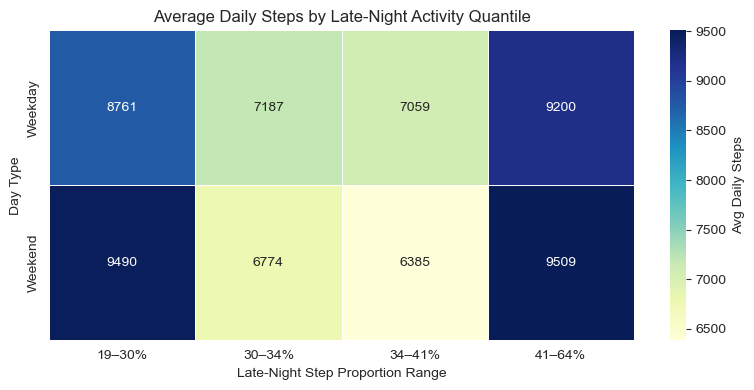

In [107]:
# Create 4 quantile bins based on late-night proportion (%)
quantiles = features_df['Prop_LateNight_Steps'] * 100
q_labels = ['Q1', 'Q2', 'Q3', 'Q4']
features_df['LateNight_Bin'] = pd.qcut(quantiles, q=4, labels=q_labels)

# Get quantile breakpoints
q_cutoffs = np.percentile(quantiles, [0, 25, 50, 75, 100])
q_labels_detailed = [
    f"{int(q_cutoffs[i])}–{int(q_cutoffs[i+1])}%" for i in range(len(q_cutoffs)-1)
]

# Melt weekday/weekend columns
heatmap_df = features_df.melt(
    id_vars=['Id', 'LateNight_Bin'],
    value_vars=['Avg_Weekday_Steps', 'Avg_Weekend_Steps'],
    var_name='DayType',
    value_name='Avg_Steps'
)
heatmap_df['DayType'] = heatmap_df['DayType'].replace({
    'Avg_Weekday_Steps': 'Weekday',
    'Avg_Weekend_Steps': 'Weekend'
})

# Compute average daily steps within each quantile and day type
pivot = heatmap_df.groupby(['DayType', 'LateNight_Bin'], observed=True)[
    'Avg_Steps'].mean().reset_index()
pivot_table = pivot.pivot(
    index='DayType', columns='LateNight_Bin', values='Avg_Steps')

print(pivot)
plt.figure(figsize=(8, 4))
sns.heatmap(
    pivot_table,
    annot=True, fmt=".0f", cmap="YlGnBu",
    linewidths=0.5, cbar_kws={'label': 'Avg Daily Steps'}
)

# Replace quantile bin names with actual percentage ranges
plt.xticks(
    ticks=np.arange(len(q_labels_detailed)) + 0.5,
    labels=q_labels_detailed,
    rotation=0
)

plt.xlabel('Late-Night Step Proportion Range')
plt.ylabel('Day Type')
plt.title('Average Daily Steps by Late-Night Activity Quantile')
plt.tight_layout()
plt.show()

### Key Findings

#### 1. Late-Night Activity Distribution
Among 32 users, late-night activity varied substantially.
- Average late-night steps: 70.6 steps/hour vs. 461.0 steps/hour during daytime.
- The median late-night/daytime ratio of 0.10 indicates that, on average, users were about 10% as active at night as during the day, though some showed obviously higher ratios.

#### 2. Relationship to Overall Activity
High late-night activity users averaged 316.6 steps/hour, compared to 376.6 steps/hour in the low late-night group.
- t(30) = -1.30, p = 0.204

**Interpretation:** Late-night activity does not reflect greater total activity level. Instead, it suggests a redistribution of activity timing rather than increased overall activity.

#### 3. Association with Sleep/Wake Patterns:
Late-night activity strongly aligns with users' sleep/wake behaviors:  
- Late Sleepers / Late Risers: 100% had high late-night activity.
- Early Sleepers / Early Risers: 77.8% had low late-night activity.
- Early Sleepers / Late Risers: mixed pattern (71.4% high late-night).

These results suggest that late-night behavior is primarily driven by later sleep schedules, consistent with a delayed sleep/wake time.

#### 4. Hourly Pattern Differences
- High late-night users maintained elevated activity past 8-9 PM, with later morning onset.
- Low late-night users showed clear declines after 9 PM and earlier peaks in the morning.  

These patterns reinforce that late-night activity reflects shifted daily timing.

### Summary Interpretation
While half of users exhibited measurable late-night movement, this behavior did not correspond to higher overall activity levels.  
Instead, it highlights how individual sleep-wake patterns and circadian timing influence when, rather than how much, people move.

### Additional analysis

#### One-way ANOVA

We'll also use a One-way ANOVA to test for a difference between the sleep/wake patterns.

Before we do so, we need to test for the assumptions first:
- Independence of observations: Each data point must be independent of all others.
- Normality of residuals: The residuals (differences between each observation and its group mean) should be approximately normally distributed.
- Homogeneity of variances: All groups should have roughly equal variance.

Since each row corresponds to one unique user after data cleaning, we have independence of observations. Now we will test for the other two assumptions.

In [108]:
from statsmodels.formula.api import ols
from scipy.stats import levene

We'll use the Shapiro-Wilk normality to test for the normality of residuals, and the hypothesis are as follows:

$H\_{0}$(p>0.05): Residuals have a normal distribution\
$H\_{1}$(p<0.05): Residuals do not have a normal distribution

In [109]:
model = ols("Avg_Daily_Steps ~ C(sleep_wake_pattern)", data=features_merged).fit()
residuals = model.resid

# Shapiro–Wilk normality test
stat, p = shapiro(residuals)
print(f"Shapiro-Wilk test: W={stat:.3f}, p={p:.3f}")

Shapiro-Wilk test: W=0.977, p=0.723


Since the p-value are way larger than 0.05, we can safely assume the normality of residuals.

**Homogeneity of variances**

For this one, the hypothesis are:

$H\_{0}$(p>0.05): Equal variances between different groups \
$H\_{1}$(p<0.05): Different variances between the groups

In [110]:
groups = [group["Avg_Daily_Steps"].values
          for name, group in features_merged.groupby("sleep_wake_pattern")]

stat, p = levene(*groups)
print(f"Levene’s test: W={stat:.3f}, p={p:.3f}")

Levene’s test: W=2.864, p=0.073


This p-value still larger 0.05, so we can assume equal variance between the groups.

The hypothesis for the **One-way ANOVA** itself are the follows:

$H\_{0}$(p>0.05): No significant diffrence between the variance of the groups\
$H\_{1}$(p<0.05): Significant diffrence between the variance of the groups

In [111]:
groups = [group["Avg_Daily_Steps"].values
          for name, group in features_merged.groupby("sleep_wake_pattern")]

model = ols("Avg_Daily_Steps ~ C(sleep_wake_pattern)",
            data=features_merged).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
print(anova_table)

                             sum_sq    df         F    PR(>F)
C(sleep_wake_pattern)  3.449218e+05   2.0  0.016402  0.983741
Residual               3.049321e+08  29.0       NaN       NaN


Because the p-value are way larger than 0.05, we fail to reject the null hypothesis that there any significant difference between the groups, which meant statistical tests have strong evidence that average daily steps does NOT depend on sleep/wake patterns.

#### PCA

We could also perform an analysis on the period of evening and late-night combined to gain some additional insights into the step behaviour patterns.

In [112]:
pca_features = [
    'Prop_LateNight_Steps',
    'Avg_LateNight_Steps',
    'Avg_Evening_Steps',
    'Prop_Evening_Steps'
]

X_pca = features_df[pca_features].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_pca)

pca = PCA(n_components=2)
X_pca_reduced = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(X_pca_reduced, columns=['PC1', 'PC2'])
features_pca = pd.concat([features_df, pca_df], axis=1)
features_pca.to_csv("features_pca.csv", index=False)

explained = pca.explained_variance_ratio_
print(f"Explained variance by components: {explained}")
print(f"Cumulative variance: {explained.sum():.2%}")

Explained variance by components: [0.53734649 0.33023653]
Cumulative variance: 86.76%


In [113]:
loadings = pd.DataFrame(
    pca.components_,
    columns=pca_features,
    index=['PC1', 'PC2']
)
loadings.round(3)

,Prop_LateNight_Steps,Avg_LateNight_Steps,Avg_Evening_Steps,Prop_Evening_Steps
PC1,-0.493,-0.293,0.545,0.612
PC2,0.405,0.729,0.502,0.227


PCA analysis have drawn out two component axis:
- PC1 have negative loadings for latenight steps, but strong positive loadings for evening steps, meaning that it was a contrast between latenight and evening activity.
- PC2 have positive loadings for all of the variables, so it was a intensity axis that is directly related to the general activity of the users.

In [114]:
X = sm.add_constant(features_pca[['PC1', 'PC2']])
y = features_pca['Avg_Daily_Steps']

model_pca = sm.OLS(y, X).fit()
compact_summary(model_pca)

p = 0.0002
R² = 0.432 | Adj R² = 0.394
Adj R² = 0.394
F-statistic: 11.408


,coef,t,p
const,8115.6656,19.1040,0.0000
PC1,-69.2098,-0.2388,0.8128
PC2,1763.3637,4.7707,0.0000


Interesting observations are being made:
- PC1 shows a very high p-value and a very low coefficient, meaning that it virtually had no effect on average daily steps.
- However, PC2 has a very low p-value and a very high coefficient, which meant activity through both of the time windows are much more impactful.

This shows that the general daily step behaviour is affected mainly by sustained activity through both of the evening and late-night time windows, rather than preference for either of the time windows alone.

# Conclusion

In relation to our driving problem (**Do participants show variation in activity levels depending on their sleep/wake times or late-night activity?**), we have found that participants do not show significant variation in activity levels depending on sleep/wake times, or late-night activity. Of the three, we think late-night activity or the lack thereof, is the strongest predictor due to its associated boxplot showing evidence of predictability with less late-night activity showing signs of more daytime activity, however, with a p-value of 0.204 it was not significant enough to demonstrate this "variation" the question requires.

## Final Results and Conclusions

### Summary of Findings  
Our analyses collectively addressed the driving question:  
**“Do participants show variation in activity levels depending on their sleep/wake times or late-night activity?”**

The dataset contained **33 users** observed over **30 days** (2016-04-12 → 2016-05-12), with high data retention (**87.3% of daily records** after cleaning).  
Most users maintained consistent device wear, averaging **24.7 valid days per participant**, confirming sufficient data for behavioral analysis.

Sleep and wake detection succeeded for **32 of 33 users (97.0%)**, revealing an average **sleep duration of 6.2 hours**, **mean sleep start time of 0.3 h (≈12:18 AM)**, and **mean wake time of 6.5 h (≈6:30 AM)**.  
The resulting classification showed:
- **Early Sleeper / Early Riser:** 18 users (56.2%)  
- **Early Sleeper / Late Riser:** 7 users (21.9%)  
- **Late Sleeper / Late Riser:** 7 users (21.9%)  
- **Late Sleeper / Early Riser:** 0 users (0%)

These patterns indicate a generally regular circadian rhythm, with only a subset showing delayed sleep and wake schedules.

---

### Late-Night Activity and Its Relationship to Daily Performance  
We defined **late-night activity** as the average hourly step count between **22:00 – 04:00**, relative to daytime (06:00 – 22:00).  
Across users:  
- **Mean late-night steps:** 70.6 steps/hour  
- **Mean daytime steps:** 461.0 steps/hour  
- **Median late-night / daytime ratio:** 0.10  

Classification produced **16 high** and **16 low late-night activity** participants (median split).  
A Welch’s t-test comparing overall activity revealed:  
`t(30) = -1.30, p = 0.204` → no statistically significant difference in total daily activity.  
High late-night users averaged **316.6 steps/hour**, whereas low late-night users averaged **376.6 steps/hour** — indicating a **redistribution of activity timing** rather than greater movement.

When combined with sleep/wake categories:
- **100% of Late Sleepers / Late Risers** exhibited **high late-night activity**.  
- **77.8% of Early Sleepers / Early Risers** exhibited **low late-night activity**.  
- **71.4% of Early Sleepers / Late Risers** showed mixed behavior.  

These relationships confirm that late-night movement primarily reflects **delayed sleep schedules** rather than increased physical engagement.

---

### Data Quality and Adherence Validation  
To ensure validity, we examined adherence across the full observation period (30 days × 33 users = 990 potential records).  
After cleaning, adherence averaged **>85%**, with only a few participants showing extended zero/missing sequences.  
Welch’s t-test between high- and low-adherence groups was inconclusive (not enough samples per group), and the Pearson correlation between adherence and daily variability yielded  
`r = 0.246, p = 0.167`, suggesting **no significant relationship** between adherence and activity stability.  
Hence, main conclusions are **robust to data completeness differences**.

---

### Integrated Interpretation  
Synthesizing all analyses:
1. **Sleep Timing:** Later sleepers and risers demonstrate reduced and delayed daily activity.  
2. **Late-Night Behavior:** Night-active participants do not exhibit higher total activity — instead, their daily peak shifts to later hours.  
3. **Circadian Consistency:** Participants with regular (early) sleep schedules show higher daytime activity and earlier peak times.  
4. **Data Robustness:** Findings persist even after filtering low-adherence participants (≥ 50% valid days).

Overall, **late-night activity and sleep/wake patterns appear to influence when activity occurs during the day, but not the total amount of activity**. The observed differences in activity distribution primarily reflect timing preferences rather than differences in overall activity levels.

---

### Limitations and Future Directions  
- Observation covers only one month and 33 participants → larger, longitudinal data would strengthen generalization.  
- Sleep periods inferred from inactivity, not verified via physiological sleep sensors.  
- External lifestyle or occupational factors were not controlled.  

Future analyses should integrate **heart-rate, sleep-stage, and contextual data (e.g., work/school schedules)** to improve behavioral interpretability.

---

### Conclusion  
The study demonstrates that while there are observable patterns in sleep/wake timing and late-night behavior, these variations do not statistically significantly affect overall daily activity levels.

Although participants show different patterns in how they distribute activity throughout the day based on their sleep/wake schedules, these differences primarily reflect timing redistribution rather than changes in total activity volume.

These results suggest that individual chronotype and sleep preferences may influence when people are active, but not necessarily how active they are overall.


# Appendix

### 1.1

A full description of the `feature_df` table:


| Column Name              | Data Type | Description |
|--------------------------|-----------|-------------|
| Id                       | int64     | Unique identifier for each user (participant) in the dataset. Serves as the primary key for merging and grouping features. |
| Avg_Daily_Steps          | float64   | Mean total steps per day for the user, aggregated across all recorded days. Represents the user's overall average daily activity level. |
| Std_Daily_Steps          | float64   | Standard deviation of total daily steps for the user. Measures the variability in daily step counts; filled with 0 where undefined (e.g., single-day data). |
| Prop_Low_Activity_Days   | float64   | Proportion of days where the user's total steps were less than 1,000. Indicates the frequency of sedentary or low-activity days. |
| Prop_Weekend_Days        | float64   | Proportion of recorded days that fall on weekends (Saturday or Sunday). Used for contextual validation of behavioral patterns. |
| Avg_LateNight_Steps      | float64   | Average steps taken during late-night periods (10 PM–6 AM), computed per user and filled with 0 for missing values. |
| Avg_Morning_Steps        | float64   | Average steps taken during morning periods (6 AM–11 AM), computed per user and filled with 0 for missing values. |
| Avg_Afternoon_Steps      | float64   | Average steps taken during afternoon periods (2 PM–6 PM), computed per user and filled with 0 for missing values. |
| Avg_Evening_Steps        | float64   | Average steps taken during evening periods (7 PM–10 PM), computed per user and filled with 0 for missing values. |
| Total_Steps              | float64   | Sum of the four average time-period steps (Morning + Afternoon + Evening + Late Night). Represents the user's total average steps across defined periods. |
| Prop_Morning_Steps       | float64   | Proportion of total average steps occurring in the morning period. Filled with 0 where total steps are zero to avoid division errors. |
| Prop_Afternoon_Steps     | float64   | Proportion of total average steps occurring in the afternoon period. Filled with 0 where total steps are zero to avoid division errors. |
| Prop_Evening_Steps       | float64   | Proportion of total average steps occurring in the evening period. Filled with 0 where total steps are zero to avoid division errors. |
| Prop_LateNight_Steps     | float64   | Proportion of total average steps occurring in the late-night period. Filled with 0 where total steps are zero to avoid division errors. |
| Avg_Weekday_Steps        | float64   | Mean total steps on weekdays (Monday–Friday), aggregated per user and filled with 0 for missing values. |
| Avg_Weekend_Steps        | float64   | Mean total steps on weekends (Saturday–Sunday), aggregated per user and filled with 0 for missing values. |
| Hourly_Step_Variance     | float64   | Standard deviation of hourly step totals across all recorded hours for the user. Captures intra-day variability in activity; filled with 0 where undefined or missing. |